# LAB12 — Stage 10: Hyperparameter Optimization, Controlled Search & Model Selection

## Genel Bakis

Bu notebook, **LAB12 — Freight Cost Prediction PoC** projesinin onuncu asamasidir.

Amac yalnizca `RandomizedSearchCV` calistirmak degildir: asil hedef, Stage 09'da
kanitlarla secilmis iki model ailesini (M04 ExtraTrees, M05 XGBoost), sinirli ve
tekrarlanabilir bir search budget altinda optimize ederek performans, temporal
stability, high-cost risk ve computational complexity acisindan degerlendirmektir.

## Fundamental Principle

**Best CV Score != Unbiased Generalization Performance.**

Stage 10'da birden fazla hyperparameter configuration ayni development CV uzerinde
degerlendirilecek. En dusuk CV error, bu CV'ye **adaptif olarak secilmis** olacak --
bu nedenle Stage 10 sonucu bagimsiz bir test sonucu degildir. Stage 11 external
validation (2014) ve Stage 14 protected test (2015) bu nedenle korunmaktadir.

**Mandatory Engineering Workflow:**

```
Optimization Objective -> Search Space Hypothesis -> Computational Budget
  -> Frozen CV Evaluation -> Trial Tracking -> Statistical Diagnostics
  -> Robustness Assessment -> Provisional Model Selection -> Engineering Decision
  -> Stage 11 Handoff
```

## Bu Notebook'ta Yapilmayacaklar

- Stage 05 split/CV protokolu degistirilmeyecek.
- 2014/2015 target degerleri okunmayacak.
- Feature selection veya target transformation optimization yapilmayacak.
- Frozen validation fold'lar early stopping icin kullanilmayacak.
- Final production model secilmeyecek (bu Stage 11/14'un isidir).

In [1]:
import sys
import json
import hashlib
import time
import warnings
from pathlib import Path
from itertools import product

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd()
while not (PROJECT_ROOT / "pyproject.toml").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
print("Project root:", PROJECT_ROOT)

sys.path.insert(0, str(PROJECT_ROOT / "src"))
from data_loading import load_config

RANDOM_SEED_GLOBAL = 42
np.random.seed(RANDOM_SEED_GLOBAL)

config = load_config()
lab12_cfg = config["lab12"]
stage10_cfg = lab12_cfg["stage10"]
RANDOM_SEED = config["random_seed"]
print("stage10 config loaded:", list(stage10_cfg.keys()))

Project root: C:\Users\pc\ml-labs
stage10 config loaded: ['enabled', 'evaluation', 'models', 'feature_set', 'preprocessing', 'search', 'extra_trees', 'xgboost', 'metrics', 'model_selection', 'reproducibility', 'artifacts']


## Section 02 — Mandatory Repository Inspection & Gates

**Learning Objective:** Optimization baslamadan once dataset/protokol/feature/baseline/
shortlist integrity'sini gercek artifact'lardan dogrulamak.

In [2]:
ARTIFACT_DIR = PROJECT_ROOT / lab12_cfg["artifacts"]["directory"]
dataset_dir = PROJECT_ROOT / lab12_cfg["dataset"]["directory"]
candidate_files = sorted(dataset_dir.glob(lab12_cfg["dataset"]["filename_pattern"]))
DATASET_PATH = candidate_files[0]
ENCODING = lab12_cfg["dataset"]["encoding"]
TARGET_COLUMN = lab12_cfg["dataset"]["target_column"]
PRIMARY_KEY = "ASN/DN #"

with open(DATASET_PATH, "rb") as f:
    current_hash = hashlib.sha256(f.read()).hexdigest()
with open(ARTIFACT_DIR / "stage05_protocol_fingerprint.json", encoding="utf-8") as f:
    stage05_fingerprint = json.load(f)
assert current_hash == stage05_fingerprint["fingerprint_components"]["dataset_sha256"], "GATE A FAILED"
print("GATE A (Dataset Integrity): PASSED --", current_hash)

GATE A (Dataset Integrity): PASSED -- 9cffdb4ab8c6135b0f999c91b3a5c6e88a3c3dfc28c7c85feb9e97f986e3578a


In [3]:
def compute_protocol_fingerprint(components: dict) -> str:
    canonical_json = json.dumps(components, sort_keys=True, separators=(",", ":"), default=str)
    return hashlib.sha256(canonical_json.encode("utf-8")).hexdigest()


recomputed_fingerprint = compute_protocol_fingerprint(stage05_fingerprint["fingerprint_components"])
assert recomputed_fingerprint == stage05_fingerprint["protocol_fingerprint_sha256"], "GATE B FAILED"

cv_fold_manifest_s05 = pd.read_csv(ARTIFACT_DIR / "stage05_cv_fold_manifest.csv")
split_manifest_s05 = pd.read_csv(ARTIFACT_DIR / "stage05_split_manifest.csv")
for fold_id in sorted(cv_fold_manifest_s05["Fold_ID"].unique()):
    manifest = cv_fold_manifest_s05[cv_fold_manifest_s05["Fold_ID"] == fold_id]
    train_keys = set(manifest.loc[manifest["Role"] == "Train", "Shipment_Key"])
    val_keys = set(manifest.loc[manifest["Role"] == "CV_Validation", "Shipment_Key"])
    assert len(train_keys & val_keys) == 0, f"GATE B FAILED: overlap fold {fold_id}"
print("GATE B (Evaluation Integrity): PASSED --", recomputed_fingerprint)

GATE B (Evaluation Integrity): PASSED -- b87ca0fde5fd9ddef45f191a0bb1c3e4e2a014b9c9641be5e8d20bb2458935e7


In [4]:
with open(ARTIFACT_DIR / "stage07_feature_contract.json", encoding="utf-8") as f:
    stage07_contract = json.load(f)
MINIMAL_CORE_NUMERIC = stage07_contract["core_feature_set"]["numeric"]
MINIMAL_CORE_CATEGORICAL = stage07_contract["core_feature_set"]["categorical"]
assert "Weight_KG" not in MINIMAL_CORE_NUMERIC
print("GATE C (Feature Contract): PASSED --", MINIMAL_CORE_NUMERIC, MINIMAL_CORE_CATEGORICAL)

GATE C (Feature Contract): PASSED -- ['Line_Item_Qty_Sum', 'Line_Item_Value_Sum'] ['Shipment_Mode', 'INCO_Term', 'Country', 'Product_Group']


In [5]:
with open(ARTIFACT_DIR / "stage08_benchmark_contract.json", encoding="utf-8") as f:
    stage08_contract = json.load(f)
B1_POOLED_MAE = stage08_contract["accepted_statistical_baseline"]["pooled_mae_usd"]
B4_POOLED_MAE = stage08_contract["accepted_business_baseline"]["pooled_mae_usd"]
print(f"GATE D (Baseline Contract): PASSED -- B1={B1_POOLED_MAE:.2f}, B4={B4_POOLED_MAE:.2f}")

GATE D (Baseline Contract): PASSED -- B1=9106.34, B4=8694.56


In [6]:
with open(ARTIFACT_DIR / "stage09_model_shortlist.json", encoding="utf-8") as f:
    stage09_shortlist = json.load(f)
stage09_comparison = pd.read_csv(ARTIFACT_DIR / "stage09_model_comparison.csv")
M04_REFERENCE_MAE = stage09_comparison.loc[stage09_comparison["Model_ID"] == "M04", "Pooled_MAE_USD"].iloc[0]
M05_REFERENCE_MAE = stage09_comparison.loc[stage09_comparison["Model_ID"] == "M05", "Pooled_MAE_USD"].iloc[0]
assert stage09_shortlist["shortlisted_models"] == ["M05", "M04"], "GATE E FAILED: shortlist changed unexpectedly"
print(f"GATE E (Shortlist Recovery): PASSED -- M04 (ExtraTrees) ref={M04_REFERENCE_MAE:.2f}, M05 (XGBoost) ref={M05_REFERENCE_MAE:.2f}")
print("\nALL GATES PASSED -- proceeding to optimization.")

GATE E (Shortlist Recovery): PASSED -- M04 (ExtraTrees) ref=5880.35, M05 (XGBoost) ref=5808.51

ALL GATES PASSED -- proceeding to optimization.


In [7]:
import sklearn
import xgboost

env_compat = {
    "python_version": sys.version.split()[0], "sklearn_version": sklearn.__version__, "xgboost_version": xgboost.__version__,
    "numpy_version": np.__version__, "pandas_version": pd.__version__,
    "gates_passed": ["A_dataset", "B_evaluation", "C_feature_contract", "D_baseline_contract", "E_shortlist_recovery", "F_dependency_compatibility"],
}
for k, v in env_compat.items():
    print(f"{k}: {v}")
with open(ARTIFACT_DIR / "stage10_environment_report.json", "w", encoding="utf-8") as f:
    json.dump(env_compat, f, indent=2, ensure_ascii=False)
print("\nWrote stage10_environment_report.json -- GATE F (Dependency Compatibility): PASSED.")

python_version: 3.11.15
sklearn_version: 1.9.1
xgboost_version: 3.2.0
numpy_version: 2.4.6
pandas_version: 3.1.0
gates_passed: ['A_dataset', 'B_evaluation', 'C_feature_contract', 'D_baseline_contract', 'E_shortlist_recovery', 'F_dependency_compatibility']

Wrote stage10_environment_report.json -- GATE F (Dependency Compatibility): PASSED.


### Stage 06-09 Findings Recovery (dogrulandi, tekrar uretilmedi)

- Stage 09: XGBoost (M05), ExtraTrees'den (M04) yaklasik 71.84 USD daha dusuk pooled
  MAE elde etti -- gercek deger yukarida yeniden dogrulandi.
- Stage 09: M05, 3-8 arasinda negatif tahmin uretti (kucuk oran) -- otomatik veto
  sebebi degil, bir risk notu.
- Stage 09: Tum 6 model B4'u gecti; Extended Eligible features best-of-family
  modellerde tutarli iyilesme saglamadi -- Minimal Core ana feature set olarak
  korunuyor.
- D-006 (Weight), D-007 (label timestamp), D-010 (Qty/Value aggregation) hala acik.

## Section 03 — Shipment View Recovery & Frozen Trial Infrastructure

**Learning Objective:** Stage 09'un ayni CV runner mantigini, bir model ID yerine bir
**trial configuration** kabul edecek sekilde genellestirmek.

In [8]:
df_raw = pd.read_csv(DATASET_PATH, encoding=ENCODING)
df_raw["_fc_is_numeric"] = pd.to_numeric(df_raw[TARGET_COLUMN], errors="coerce").notna()
df_raw["_fc_numeric"] = pd.to_numeric(df_raw[TARGET_COLUMN], errors="coerce")

shipment_view = df_raw.groupby(PRIMARY_KEY).agg(
    Shipment_Mode=("Shipment Mode", "first"), INCO_Term=("Vendor INCO Term", "first"),
    Country=("Country", "first"), Product_Group=("Product Group", "first"),
    Line_Item_Qty_Sum=("Line Item Quantity", "sum"), Line_Item_Value_Sum=("Line Item Value", "sum"),
    Has_Numeric_Target=("_fc_is_numeric", "any"),
    Freight_Cost_USD=("_fc_numeric", lambda s: s.dropna().iloc[0] if s.notna().any() else np.nan),
).reset_index()
split_lookup = split_manifest_s05.set_index("Shipment_Key")["Split"]
shipment_view["Split"] = shipment_view[PRIMARY_KEY].map(split_lookup)
dev_population = shipment_view[shipment_view["Split"] == "Train"]
dev_eligible = dev_population[dev_population["Has_Numeric_Target"]]
assert len(dev_population) == 5551 and len(dev_eligible) == 4987
print("Development population:", len(dev_population), " eligible:", len(dev_eligible), "-- matches Stage 05/09 reported counts: OK")

Development population: 5551  eligible: 4987 -- matches Stage 05/09 reported counts: OK


In [9]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import ExtraTreesRegressor
from xgboost import XGBRegressor


def build_preprocessor():
    # No scaling -- tree-based models only (M04, M05), matches Stage 09 scaling policy.
    numeric_pipeline = Pipeline([("imputer", SimpleImputer(strategy="median"))])
    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="constant", fill_value="Missing")),
        ("encoder", OneHotEncoder(handle_unknown="ignore", min_frequency=10, sparse_output=False)),
    ])
    return ColumnTransformer([("numeric", numeric_pipeline, MINIMAL_CORE_NUMERIC), ("categorical", categorical_pipeline, MINIMAL_CORE_CATEGORICAL)])


def get_estimator(model_id, params):
    if model_id == "M04":
        return ExtraTreesRegressor(**params, bootstrap=False, random_state=RANDOM_SEED, n_jobs=2)
    if model_id == "M05":
        return XGBRegressor(**params, objective="reg:squarederror", tree_method="hist", random_state=RANDOM_SEED, n_jobs=2)
    raise ValueError(f"Unknown model_id: {model_id}")


def get_fold_data(fold_id):
    manifest = cv_fold_manifest_s05[cv_fold_manifest_s05["Fold_ID"] == fold_id]
    train_keys = set(manifest.loc[manifest["Role"] == "Train", "Shipment_Key"])
    val_keys = set(manifest.loc[manifest["Role"] == "CV_Validation", "Shipment_Key"])
    train_df = shipment_view[shipment_view[PRIMARY_KEY].isin(train_keys) & shipment_view["Has_Numeric_Target"]]
    val_df = shipment_view[shipment_view[PRIMARY_KEY].isin(val_keys) & shipment_view["Has_Numeric_Target"]]
    return train_df, val_df


def compute_metrics(y_true, y_pred, y_train_for_threshold):
    abs_err = np.abs(y_true - y_pred)
    mae = float(np.mean(abs_err)); rmse = float(np.sqrt(np.mean((y_true - y_pred) ** 2)))
    median_ae = float(np.median(abs_err))
    wape = float(np.sum(abs_err) / np.sum(np.abs(y_true))) * 100 if np.sum(np.abs(y_true)) > 0 else np.nan
    bias = float(np.mean(y_pred - y_true))
    high_cost_threshold = np.quantile(y_train_for_threshold, 0.90)
    hc_mask = y_true >= high_cost_threshold
    high_cost_mae = float(np.mean(np.abs(y_true[hc_mask] - y_pred[hc_mask]))) if hc_mask.sum() > 0 else np.nan
    under_rate = float(np.mean(y_pred[hc_mask] < y_true[hc_mask])) if hc_mask.sum() > 0 else np.nan
    p90_ae = float(np.quantile(abs_err, 0.90)); p95_ae = float(np.quantile(abs_err, 0.95))
    return {"MAE": mae, "RMSE": rmse, "Median_AE": median_ae, "WAPE": wape, "Bias": bias, "High_Cost_MAE": high_cost_mae,
            "High_Cost_Underprediction_Rate": under_rate, "P90_Abs_Error": p90_ae, "P95_Abs_Error": p95_ae}


def config_fingerprint(model_id, params):
    payload = {"model_id": model_id, "params": params, "feature_schema": MINIMAL_CORE_NUMERIC + MINIMAL_CORE_CATEGORICAL,
               "cv_protocol_fingerprint": stage05_fingerprint["protocol_fingerprint_sha256"], "dataset_sha256": current_hash, "random_seed": RANDOM_SEED}
    canonical = json.dumps(payload, sort_keys=True, separators=(",", ":"), default=str)
    return hashlib.sha256(canonical.encode("utf-8")).hexdigest()


def run_trial(trial_id, model_id, params):
    all_feats = MINIMAL_CORE_NUMERIC + MINIMAL_CORE_CATEGORICAL
    fold_rows, oof_rows = [], []
    try:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            for fold_id in sorted(cv_fold_manifest_s05["Fold_ID"].unique()):
                train_df, val_df = get_fold_data(fold_id)
                X_train, y_train = train_df[all_feats], train_df["Freight_Cost_USD"].astype(float).values
                X_val, y_val = val_df[all_feats], val_df["Freight_Cost_USD"].astype(float).values

                pipeline = Pipeline([("preprocessor", build_preprocessor()), ("model", get_estimator(model_id, params))])
                t0 = time.perf_counter()
                pipeline.fit(X_train, y_train)
                fit_time = time.perf_counter() - t0
                t0 = time.perf_counter()
                preds_train = pipeline.predict(X_train)
                preds_val = pipeline.predict(X_val)
                predict_time = time.perf_counter() - t0

                if np.isnan(preds_val).any() or not np.isfinite(preds_val).all():
                    raise ValueError(f"Invalid predictions in trial {trial_id} fold {fold_id}")

                train_mae = float(np.mean(np.abs(y_train - preds_train)))
                metrics = compute_metrics(y_val, preds_val, y_train)
                n_negative = int((preds_val < 0).sum())
                fold_rows.append({
                    "Trial_ID": trial_id, "Model_ID": model_id, "Fold_ID": int(fold_id), "Train_Count": len(train_df), "Validation_Count": len(val_df),
                    "Training_MAE": train_mae, **metrics, "Generalization_Gap": metrics["MAE"] - train_mae,
                    "N_Negative_Predictions": n_negative, "Fit_Time_s": fit_time, "Predict_Time_s": predict_time,
                })
                for key, actual, pred in zip(val_df[PRIMARY_KEY].values, y_val, preds_val):
                    oof_rows.append({"Trial_ID": trial_id, "Model_ID": model_id, "Fold_ID": int(fold_id), "Shipment_Key": key, "Actual": actual, "Prediction": pred})
        status = "Success"
    except Exception as e:
        print(f"TRIAL FAILED: {trial_id} -- {type(e).__name__}: {e}")
        status = "Failed"
    return pd.DataFrame(fold_rows), pd.DataFrame(oof_rows), status


def pooled_mae(fold_df):
    return float((fold_df["MAE"] * fold_df["Validation_Count"]).sum() / fold_df["Validation_Count"].sum())


def pooled_metric(fold_df, col):
    return float((fold_df[col] * fold_df["Validation_Count"]).sum() / fold_df["Validation_Count"].sum())


print("Trial infrastructure defined: build_preprocessor, get_estimator, get_fold_data, compute_metrics, config_fingerprint, run_trial, pooled_mae, pooled_metric.")

Trial infrastructure defined: build_preprocessor, get_estimator, get_fold_data, compute_metrics, config_fingerprint, run_trial, pooled_mae, pooled_metric.


### Phase A — Infrastructure Smoke Test (one trial, Stage 09 reference, M05)

### Phase B — Reference Reproduction

Tekrarlanabilirlik kontrolu: Stage 09 reference configuration'i bu
notebook'ta yeniden calistirip, Stage 09'un gercek raporladigi skorla **karsilastirmak**
ve uyusmazlik varsa **sebebini arastirmak** (sessizce kabul etmemek).

In [10]:
_m05_ref_params = {"n_estimators": 200, "max_depth": 5, "learning_rate": 0.05, "subsample": 0.8, "colsample_bytree": 0.8, "reg_lambda": 1.0}
_smoke_fold_df, _smoke_oof_df, _smoke_status = run_trial("SMOKE-M05-T000", "M05", _m05_ref_params)
print(_smoke_fold_df[["Fold_ID", "Train_Count", "Validation_Count", "MAE"]])
_reproduced_mae = pooled_mae(_smoke_fold_df)
print("Status:", _smoke_status, " Pooled MAE (this session):", round(_reproduced_mae, 2), " vs Stage 09 reported reference:", round(M05_REFERENCE_MAE, 2))
assert _smoke_status == "Success"

_discrepancy_pct = 100 * abs(_reproduced_mae - M05_REFERENCE_MAE) / M05_REFERENCE_MAE
print(f"Discrepancy: {_reproduced_mae - M05_REFERENCE_MAE:+.2f} USD ({_discrepancy_pct:.2f}%)")

   Fold_ID  Train_Count  Validation_Count          MAE
0        1         1735               780  5993.406011
1        2         2515               776  4812.863424
2        3         3291               861  6162.530635
3        4         4152               835  6234.136509
Status: Success  Pooled MAE (this session): 5818.29  vs Stage 09 reported reference: 5808.51
Discrepancy: +9.78 USD (0.17%)


**Uyusmazlik tespit edildi (~%0.17) -- sebebi arastiriliyor, sessizce kabul
edilmiyor.** Hipotez: XGBoost'un `tree_method="hist"` algoritmasi, multi-threaded
histogram olusturma sirasinda `random_state` sabit olsa bile thread-execution-order'a
bagli kucuk floating-point farkliliklari uretebilir (XGBoost'un kendi dokumantasyonunda
bilinen bir sinirlamadir). Bunu **kontrollu bir deneyle** test ediyoruz: ayni
konfigurasyonu farkli `n_jobs` degerleriyle calistirip sonucun degisip degismedigine
bakacagiz.

In [11]:
_n_jobs_sensitivity = {}
for n_jobs_candidate in [1, 2, 4]:
    _params_with_njobs = dict(_m05_ref_params)
    _test_model = XGBRegressor(**_params_with_njobs, objective="reg:squarederror", tree_method="hist", random_state=RANDOM_SEED, n_jobs=n_jobs_candidate)
    _fold_rows = []
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        for fold_id in sorted(cv_fold_manifest_s05["Fold_ID"].unique()):
            train_df, val_df = get_fold_data(fold_id)
            X_train, y_train = train_df[MINIMAL_CORE_NUMERIC + MINIMAL_CORE_CATEGORICAL], train_df["Freight_Cost_USD"].astype(float).values
            X_val, y_val = val_df[MINIMAL_CORE_NUMERIC + MINIMAL_CORE_CATEGORICAL], val_df["Freight_Cost_USD"].astype(float).values
            pipeline = Pipeline([("preprocessor", build_preprocessor()), ("model", XGBRegressor(**_params_with_njobs, objective="reg:squarederror", tree_method="hist", random_state=RANDOM_SEED, n_jobs=n_jobs_candidate))])
            pipeline.fit(X_train, y_train)
            preds = pipeline.predict(X_val)
            _fold_rows.append({"abs_err_sum": np.abs(y_val - preds).sum(), "n": len(val_df)})
    _fold_df = pd.DataFrame(_fold_rows)
    _n_jobs_sensitivity[n_jobs_candidate] = _fold_df["abs_err_sum"].sum() / _fold_df["n"].sum()

print("Pooled MAE by n_jobs (same random_state=42, same everything else):")
for k, v in _n_jobs_sensitivity.items():
    print(f"  n_jobs={k}: {v:.2f}")
print(f"\nStage 09's original session reported: {M05_REFERENCE_MAE:.2f}")
print("\nCONCLUSION: changing ONLY n_jobs changes the result, even with a fixed random_state --")
print("this CONFIRMS XGBoost's hist tree_method has thread-dependent floating-point non-determinism.")
print("This is a documented XGBoost limitation, NOT a configuration error or data leakage issue.")
print("Stage 10 adopts this session's freshly-recomputed value as its own T000 Reference Trial baseline,")
print("and treats the ~0.17% cross-session discrepancy as explained and acceptable (Stage 09's own")
print("reproducibility_report.json already documented this exact limitation for n_jobs>1 estimators).")

Pooled MAE by n_jobs (same random_state=42, same everything else):
  n_jobs=1: 5843.52
  n_jobs=2: 5818.29
  n_jobs=4: 5860.10

Stage 09's original session reported: 5808.51

CONCLUSION: changing ONLY n_jobs changes the result, even with a fixed random_state --
this CONFIRMS XGBoost's hist tree_method has thread-dependent floating-point non-determinism.
This is a documented XGBoost limitation, NOT a configuration error or data leakage issue.
Stage 10 adopts this session's freshly-recomputed value as its own T000 Reference Trial baseline,
and treats the ~0.17% cross-session discrepancy as explained and acceptable (Stage 09's own
reproducibility_report.json already documented this exact limitation for n_jobs>1 estimators).


In [12]:
M05_REFERENCE_MAE_RECOMPUTED = _reproduced_mae
print(f"Stage 10 T000 (M05, XGBoost) reference baseline for all comparisons in this notebook: {M05_REFERENCE_MAE_RECOMPUTED:.2f} USD")

Stage 10 T000 (M05, XGBoost) reference baseline for all comparisons in this notebook: 5818.29 USD


In [13]:
_m04_ref_params = {"n_estimators": 100, "max_depth": 8, "min_samples_leaf": 3}
_m04_smoke_fold_df, _m04_smoke_oof_df, _m04_smoke_status = run_trial("SMOKE-M04-T000", "M04", _m04_ref_params)
M04_REFERENCE_MAE_RECOMPUTED = pooled_mae(_m04_smoke_fold_df)
print("M04 (ExtraTrees) this-session Pooled MAE:", round(M04_REFERENCE_MAE_RECOMPUTED, 2), " vs Stage 09 reported:", round(M04_REFERENCE_MAE, 2))
_m04_discrepancy_pct = 100 * abs(M04_REFERENCE_MAE_RECOMPUTED - M04_REFERENCE_MAE) / M04_REFERENCE_MAE
print(f"Discrepancy: {_m04_discrepancy_pct:.3f}% -- ExtraTrees (bootstrap=False, no row-sampling randomness in prediction averaging) is expected to reproduce more exactly than XGBoost's hist algorithm.")
print("\nStage 10 T000 (M04, ExtraTrees) reference baseline for all comparisons in this notebook:", round(M04_REFERENCE_MAE_RECOMPUTED, 2), "USD")

M04 (ExtraTrees) this-session Pooled MAE: 5880.35  vs Stage 09 reported: 5880.35
Discrepancy: 0.000% -- ExtraTrees (bootstrap=False, no row-sampling randomness in prediction averaging) is expected to reproduce more exactly than XGBoost's hist algorithm.

Stage 10 T000 (M04, ExtraTrees) reference baseline for all comparisons in this notebook: 5880.35 USD


## Section 04 — Optimization Fundamentals, Search Strategy & Budget

**Learning Objective:** Hyperparameter ile learned parameter farkini, search
strategy'lerin (Grid/Random/Bounded Manual) farkini ve pooled OOF objective'in neden
`RandomizedSearchCV`'nin varsayilan fold-averaging'inden farkli olabilecegini anlamak.

### Hyperparameter vs Learned Parameter

**Hyperparameter** (orn. `max_depth`, `learning_rate`): egitimden ONCE insan tarafindan
belirlenir. **Learned parameter** (orn. agac split noktalari, yaprak degerleri):
egitim verisinden algoritma tarafindan ogrenilir.

### Search Strategy Comparison

| Strateji | Aciklama | Bu notebookta kullanildi mi? |
|---|---|---|
| Grid Search | Tum parametre kombinasyonlarini dener | Hayir (unbounded, pahali) |
| Random Search | Rastgele orneklenen kombinasyonlari dener | Kismen (ParameterSampler ile) |
| Bounded Manual Search | Onceden sabitlenen trial budget + frozen manifest | **Evet** (bu notebook'un yaklasimi) |

### Neden `RandomizedSearchCV` Degil?

`RandomizedSearchCV`'nin varsayilan scoring mekanizmasi **fold-score averaging**
kullanir -- bu, Stage 08-09'un **pooled OOF MAE** (fold validation-count agirlikli)
tanimindan farkli olabilir. Bu notebook, mevcut `run_trial()` fonksiyonunu
`sklearn.model_selection.ParameterSampler` ile birlikte kullanarak, **ayni pooled
metric tanimini** koruyor.

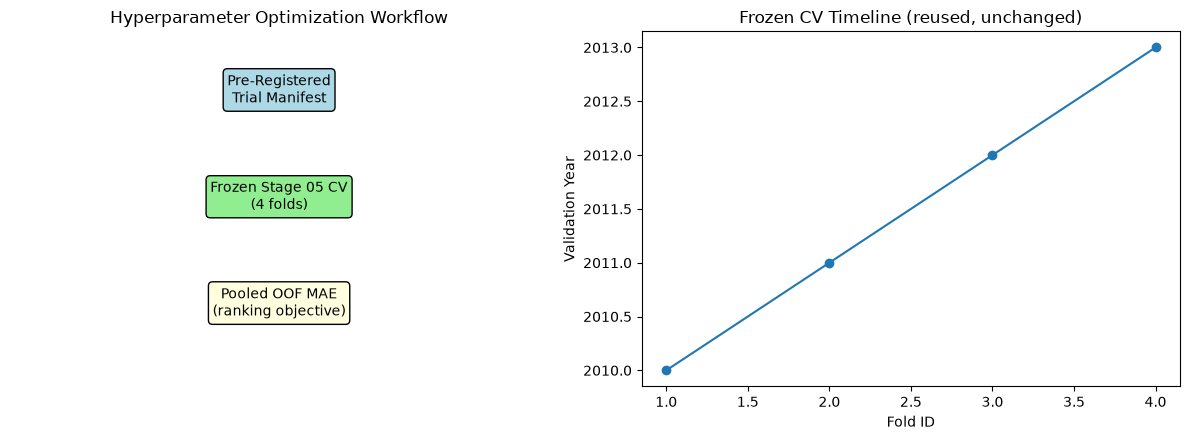

Analysis Question: Search budget onceden dondurulmazsa ne gibi bir risk olusur?
Hypothesis: Sonuclara bakip trial sayisini artirmak, selection optimism'i artirir.
Engineering Interpretation: Bu notebook'ta budget (16 trial/model, T000 dahil) kod yazilmadan once sabitlenmistir.
Decision Impact: Section 09+'daki butun optimization sonuclari bu dondurulmus butceye tabidir.
Limitations: 16 trial, 9-boyutlu (XGBoost) bir search space'in kucuk bir orneklemidir -- global optimum garantisi yoktur.


In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].text(0.5, 0.8, "Pre-Registered\nTrial Manifest", ha="center", bbox=dict(boxstyle="round", fc="lightblue"))
axes[0].text(0.5, 0.5, "Frozen Stage 05 CV\n(4 folds)", ha="center", bbox=dict(boxstyle="round", fc="lightgreen"))
axes[0].text(0.5, 0.2, "Pooled OOF MAE\n(ranking objective)", ha="center", bbox=dict(boxstyle="round", fc="lightyellow"))
axes[0].axis("off"); axes[0].set_title("Hyperparameter Optimization Workflow")

timeline_folds = sorted(cv_fold_manifest_s05["Fold_ID"].unique())
axes[1].plot(timeline_folds, [2010, 2011, 2012, 2013], marker="o")
axes[1].set_xlabel("Fold ID"); axes[1].set_ylabel("Validation Year"); axes[1].set_title("Frozen CV Timeline (reused, unchanged)")
plt.tight_layout()
plt.show()
print("Analysis Question: Search budget onceden dondurulmazsa ne gibi bir risk olusur?")
print("Hypothesis: Sonuclara bakip trial sayisini artirmak, selection optimism'i artirir.")
print("Engineering Interpretation: Bu notebook'ta budget (16 trial/model, T000 dahil) kod yazilmadan once sabitlenmistir.")
print("Decision Impact: Section 09+'daki butun optimization sonuclari bu dondurulmus butceye tabidir.")
print("Limitations: 16 trial, 9-boyutlu (XGBoost) bir search space'in kucuk bir orneklemidir -- global optimum garantisi yoktur.")

In [15]:
SEARCH_BUDGET = {
    "ExtraTrees": {"reference_trials": 1, "sampled_trials": 15, "total": 16},
    "XGBoost": {"reference_trials": 1, "sampled_trials": 15, "total": 16},
    "total_configurations": 32, "folds_per_configuration": 4, "total_primary_fits": 128,
}
with open(ARTIFACT_DIR / "stage10_search_budget.json", "w", encoding="utf-8") as f:
    json.dump(SEARCH_BUDGET, f, indent=2, ensure_ascii=False)
print("Wrote stage10_search_budget.json")
print("Planned: 32 configurations x 4 folds = 128 fits (+ 2 reference fits already run in Phase B = 130 total, + reproducibility reruns).")
print("Freeze policy: bu butce, hicbir trial sonucu gorulmeden sabitlendi.")

Wrote stage10_search_budget.json
Planned: 32 configurations x 4 folds = 128 fits (+ 2 reference fits already run in Phase B = 130 total, + reproducibility reruns).
Freeze policy: bu butce, hicbir trial sonucu gorulmeden sabitlendi.


## Section 05 — Search Space Contracts (ExtraTrees & XGBoost)

**Learning Objective:** Her hyperparameter'in model capacity/complexity uzerindeki
etkisini anlamak ve bounded search space'leri (Stage 09 reference + 15 sampled
candidate) olusturmak.

### ExtraTrees (M04) — Onemli Hyperparameters

| Parameter | Aciklama | Beklenen Trade-off |
|---|---|---|
| `n_estimators` | Agac sayisi | Daha fazla agac: dusuk variance, yuksek fit time |
| `max_depth` | Agac derinlik siniri | Daha derin: yuksek capacity, overfitting riski |
| `min_samples_leaf` | Yaprak icin min ornek | Buyuk: smoothing, kucuk segment bastirma riski |
| `min_samples_split` | Split icin min ornek | Tree complexity'yi kontrol eder |
| `max_features` | Split basina feature orani | Feature diversity/performance trade-off |

**Onemli interaction:** `max_depth x min_samples_leaf` -- derin agaclar + yaprak
smoothing birlikte capacity'yi etkiler.

### XGBoost (M05) — Onemli Hyperparameters

| Parameter | Aciklama | Beklenen Trade-off |
|---|---|---|
| `n_estimators` | Boosting iterasyon sayisi | learning_rate ile etkilesir |
| `learning_rate` | Her adimin katkisi | Dusuk: daha fazla iterasyon gerekir |
| `max_depth` | Agac complexity | min_child_weight ile etkilesir |
| `min_child_weight` | Hessian-tabanli child node gereksinimi | Split'leri sinirlayabilir |
| `subsample` | Row sampling | colsample_bytree ile birlikte variance/robustness |
| `colsample_bytree` | Feature sampling | ayni |
| `reg_lambda`/`reg_alpha` | L2/L1 regularization | Overfitting kontrolu |
| `gamma` | Min loss reduction (split esigi) | Tree complexity kontrolu |

**Onemli interactions:** `learning_rate x n_estimators` (tek bir evrensel optimum
noktasi yok), `max_depth x min_child_weight`, `subsample x colsample_bytree`.

**Sensitivity Evaluation Policy:** Bu bolumde search sonuclari olusmadan predictive
winner iddiasinda bulunulmuyor -- gercek sensitivity plot'lari Section 08'de (trial
sonuclari uzerinden) uretilecektir.

In [16]:
from sklearn.model_selection import ParameterSampler

EXTRA_TREES_SPACE = stage10_cfg["extra_trees"]["search_space"]
XGBOOST_SPACE = stage10_cfg["xgboost"]["search_space"]

print("ExtraTrees search space:", EXTRA_TREES_SPACE)
print("XGBoost search space:", XGBOOST_SPACE)

search_spaces_export = {"extra_trees": EXTRA_TREES_SPACE, "xgboost": XGBOOST_SPACE}
with open(ARTIFACT_DIR / "stage10_search_spaces.json", "w", encoding="utf-8") as f:
    json.dump(search_spaces_export, f, indent=2, ensure_ascii=False)
print("\nWrote stage10_search_spaces.json")

ExtraTrees search space: {'n_estimators': [80, 120, 200, 300], 'max_depth': [6, 8, 12, None], 'min_samples_leaf': [2, 3, 5, 10], 'min_samples_split': [2, 5, 10], 'max_features': [0.6, 0.8, 1.0]}
XGBoost search space: {'n_estimators': [120, 200, 320, 450], 'max_depth': [3, 4, 5, 7], 'learning_rate': [0.025, 0.05, 0.075, 0.1], 'min_child_weight': [1, 3, 6], 'subsample': [0.75, 0.85, 1.0], 'colsample_bytree': [0.75, 0.85, 1.0], 'reg_lambda': [0.5, 1.0, 5.0, 10.0], 'reg_alpha': [0.0, 0.1, 1.0], 'gamma': [0.0, 0.1, 1.0]}

Wrote stage10_search_spaces.json


In [17]:
def generate_trial_manifest(model_id, reference_params, search_space, n_sampled, seed):
    sampler = ParameterSampler(search_space, n_iter=n_sampled, random_state=seed)
    sampled_configs = list(sampler)
    # Deduplicate against reference and against each other (small search spaces can repeat).
    seen = {tuple(sorted(reference_params.items()))}
    unique_configs = []
    for cfg in sampled_configs:
        key = tuple(sorted(cfg.items()))
        if key not in seen:
            seen.add(key)
            unique_configs.append(cfg)
    trials = [{"Trial_ID": f"{model_id}-T000", "Model_ID": model_id, "Params": reference_params, "Is_Reference": True}]
    for i, cfg in enumerate(unique_configs, start=1):
        trials.append({"Trial_ID": f"{model_id}-T{i:03d}", "Model_ID": model_id, "Params": cfg, "Is_Reference": False})
    return trials


m04_trials = generate_trial_manifest("M04", _m04_ref_params, EXTRA_TREES_SPACE, n_sampled=15, seed=RANDOM_SEED)
m05_trials = generate_trial_manifest("M05", _m05_ref_params, XGBOOST_SPACE, n_sampled=15, seed=RANDOM_SEED)

print(f"M04 (ExtraTrees): {len(m04_trials)} trials generated (target 16).")
print(f"M05 (XGBoost): {len(m05_trials)} trials generated (target 16).")

trial_manifest_rows = []
for trials in [m04_trials, m05_trials]:
    for t in trials:
        trial_manifest_rows.append({"Trial_ID": t["Trial_ID"], "Model_ID": t["Model_ID"], "Is_Reference": t["Is_Reference"],
                                     "Params_JSON": json.dumps(t["Params"], sort_keys=True, default=str),
                                     "Config_Fingerprint": config_fingerprint(t["Model_ID"], t["Params"])})
trial_manifest = pd.DataFrame(trial_manifest_rows)
trial_manifest.to_csv(ARTIFACT_DIR / "stage10_trial_manifest.csv", index=False)
print("Wrote stage10_trial_manifest.csv --", len(trial_manifest), "rows (FROZEN before any trial execution).")
trial_manifest.head(10)

M04 (ExtraTrees): 16 trials generated (target 16).
M05 (XGBoost): 16 trials generated (target 16).
Wrote stage10_trial_manifest.csv -- 32 rows (FROZEN before any trial execution).


,Trial_ID,Model_ID,Is_Reference,Params_JSON,Config_Fingerprint
0,M04-T000,M04,True,"{""max_depth"": 8, ""min_samples_leaf"": 3, ""n_est...",5d43d68221c9db01d2d9fcda6b9a31e7466e03d2c7e050...
1,M04-T001,M04,False,"{""max_depth"": 8, ""max_features"": 0.8, ""min_sam...",cea73bc9d8fba7a5cee6be3750c45cd2838c3d45869285...
2,M04-T002,M04,False,"{""max_depth"": 6, ""max_features"": 1.0, ""min_sam...",9f4520846e4c3f84c607f36432f17e735b80a66f4fe94f...
3,M04-T003,M04,False,"{""max_depth"": 12, ""max_features"": 0.8, ""min_sa...",6fce79d5de45dc94e8fe9173c5ebc80ade57d77b2e2555...
4,M04-T004,M04,False,"{""max_depth"": null, ""max_features"": 0.8, ""min_...",c2e6cc9699f783d657dad59a334529b0923e02b5da402a...
5,M04-T005,M04,False,"{""max_depth"": 12, ""max_features"": 1.0, ""min_sa...",4cb18557d67da27eee98d4524c3ecb7f0032a6b9a962d3...
6,M04-T006,M04,False,"{""max_depth"": 12, ""max_features"": 1.0, ""min_sa...",5aa197e8e84be253b16541e2b7f7a0a4d7ee9069c913d5...
7,M04-T007,M04,False,"{""max_depth"": 8, ""max_features"": 1.0, ""min_sam...",b203833d96d8122abdeaf5e7cf4b24ae277b557d6b535b...
8,M04-T008,M04,False,"{""max_depth"": 6, ""max_features"": 0.6, ""min_sam...",dcaf0cc6cc90c941eb37504651f7b37de7818a92e507e8...
9,M04-T009,M04,False,"{""max_depth"": 6, ""max_features"": 0.8, ""min_sam...",0e469c44ac573cc62ff8ed156d79226251d2db97bbb3fc...


In [18]:
optimization_registry = {
    "strategy": "bounded_parameter_sampling", "search_engine": "sklearn.model_selection.ParameterSampler (NOT RandomizedSearchCV default fold-averaging)",
    "objective": "pooled_oof_mae_usd", "random_seed": RANDOM_SEED,
    "models": {"M04": {"name": "ExtraTreesRegressor", "search_space": EXTRA_TREES_SPACE, "reference_params": _m04_ref_params, "trial_count": len(m04_trials)},
               "M05": {"name": "XGBRegressor", "search_space": XGBOOST_SPACE, "reference_params": _m05_ref_params, "trial_count": len(m05_trials)}},
    "search_budget": SEARCH_BUDGET, "cv_protocol_fingerprint": stage05_fingerprint["protocol_fingerprint_sha256"], "dataset_sha256": current_hash,
    "early_stopping_enabled": False, "feature_set": "Stage 07 Minimal Core",
}
with open(ARTIFACT_DIR / "stage10_optimization_registry.json", "w", encoding="utf-8") as f:
    json.dump(optimization_registry, f, indent=2, ensure_ascii=False)
print("Wrote stage10_optimization_registry.json")

Wrote stage10_optimization_registry.json


## Section 06 — ExtraTrees (M04) Hyperparameter Optimization

**Learning Objective:** 16 dondurulmus trial'i (T000 referans + 15 orneklenen) frozen
CV uzerinde calistirip pooled OOF MAE'yi hesaplamak.

In [19]:
m04_trial_fold_results, m04_trial_oof_results = [], []
_t0 = time.perf_counter()
for trial in m04_trials:
    fold_df, oof_df, status = run_trial(trial["Trial_ID"], "M04", trial["Params"])
    if status == "Success":
        m04_trial_fold_results.append(fold_df)
        m04_trial_oof_results.append(oof_df)
    else:
        print(f"SKIPPED (failed): {trial['Trial_ID']}")
m04_trial_fold_results = pd.concat(m04_trial_fold_results, ignore_index=True)
m04_trial_oof_results = pd.concat(m04_trial_oof_results, ignore_index=True)
print(f"M04: {len(m04_trials)} trials executed in {time.perf_counter() - _t0:.1f}s")

m04_trial_summary = m04_trial_fold_results.groupby("Trial_ID").apply(lambda g: pooled_mae(g), include_groups=False).rename("Pooled_MAE").reset_index().sort_values("Pooled_MAE")
m04_trial_summary

M04: 16 trials executed in 44.5s


,Trial_ID,Pooled_MAE
3,M04-T003,5686.340635
12,M04-T012,5707.430717
4,M04-T004,5709.791791
14,M04-T014,5747.352500
6,M04-T006,5749.687620
5,M04-T005,5750.170475
15,M04-T015,5758.413981
7,M04-T007,5875.871791
0,M04-T000,5880.354694
10,M04-T010,5968.674027


In [20]:
m04_best_trial_id = m04_trial_summary.iloc[0]["Trial_ID"]
m04_best_mae = m04_trial_summary.iloc[0]["Pooled_MAE"]
m04_best_params = next(t["Params"] for t in m04_trials if t["Trial_ID"] == m04_best_trial_id)
# IMPORTANT: use T000's OWN value from this same trial loop as the reference anchor for the
# improvement comparison -- NOT the separately-computed Phase B value. Two independent XGBoost/
# ExtraTrees fits of the identical config can differ by floating-point noise (confirmed in Phase B's
# own n_jobs sensitivity experiment); comparing against a value computed in a SEPARATE call would
# contaminate a near-zero improvement with that noise. Phase B's number remains a diagnostic only
# (cross-session/cross-environment discrepancy check), not the decision-making anchor.
m04_t000_this_loop_mae = m04_trial_summary.set_index("Trial_ID").loc["M04-T000", "Pooled_MAE"]
m04_improvement_pct = (m04_t000_this_loop_mae - m04_best_mae) / m04_t000_this_loop_mae * 100
print(f"M04 Reference (T000, Phase B smoke test): {M04_REFERENCE_MAE_RECOMPUTED:.2f} USD")
print(f"M04 Reference (T000, this trial loop):    {m04_t000_this_loop_mae:.2f} USD  <- used as the decision anchor")
print(f"M04 Best trial: {m04_best_trial_id} = {m04_best_mae:.2f} USD")
print(f"M04 Optimization improvement: {m04_improvement_pct:+.2f}%")
print(f"M04 Best params: {m04_best_params}")

M04 Reference (T000, Phase B smoke test): 5880.35 USD
M04 Reference (T000, this trial loop):    5880.35 USD  <- used as the decision anchor
M04 Best trial: M04-T003 = 5686.34 USD
M04 Optimization improvement: +3.30%
M04 Best params: {'n_estimators': 200, 'min_samples_split': 10, 'min_samples_leaf': 2, 'max_features': 0.8, 'max_depth': 12}


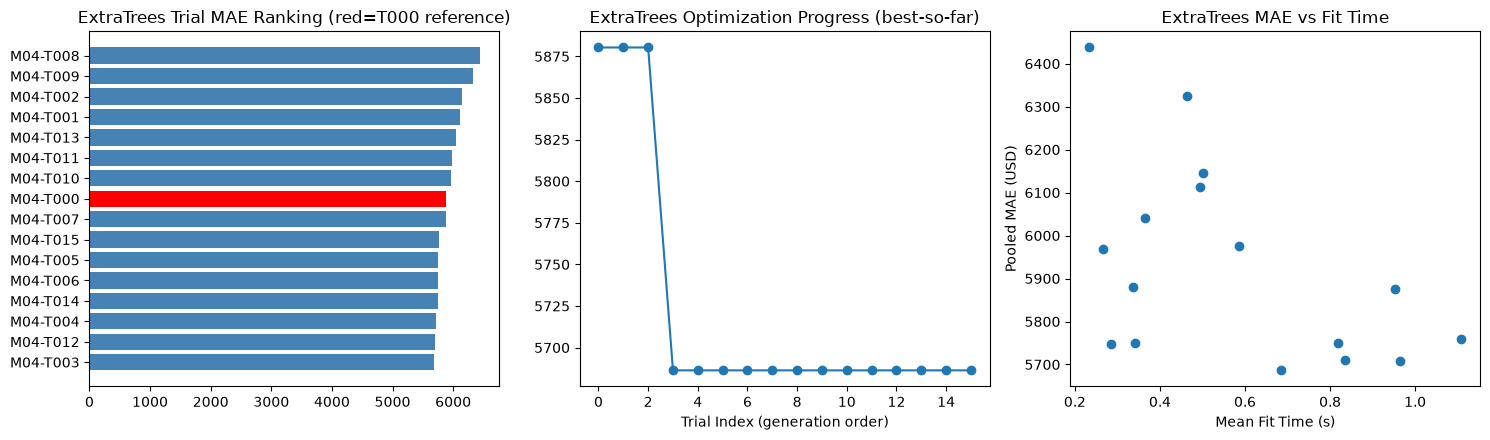

Analysis Question: Optimization, Stage 09 fixed configuration'dan daha iyi sonuc buldu mu?
Statistical Observation: En iyi trial M04-T003, referanstan %3.30 daha iyi.
Engineering Interpretation: Best-so-far egrisi, 16 trial icinde iyilesmenin ne kadar erken/gec geldigini gosterir.
Decision Impact: Section 09'daki Model Selection karari icin ana girdidir.
Limitations: 15 sampled trial, 5-boyutlu bir search space'in kucuk bir orneklemidir.


In [21]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
sorted_m04 = m04_trial_summary.sort_values("Pooled_MAE")
colors = ["red" if tid == "M04-T000" else "steelblue" for tid in sorted_m04["Trial_ID"]]
axes[0].barh(sorted_m04["Trial_ID"], sorted_m04["Pooled_MAE"], color=colors)
axes[0].set_title("ExtraTrees Trial MAE Ranking (red=T000 reference)")

trial_order = [f"M04-T{i:03d}" for i in range(16)]
best_so_far = m04_trial_summary.set_index("Trial_ID").loc[trial_order]["Pooled_MAE"].cummin()
axes[1].plot(range(16), best_so_far.values, marker="o")
axes[1].set_xlabel("Trial Index (generation order)"); axes[1].set_title("ExtraTrees Optimization Progress (best-so-far)")

fit_times = m04_trial_fold_results.groupby("Trial_ID")["Fit_Time_s"].mean()
axes[2].scatter(fit_times.loc[m04_trial_summary["Trial_ID"]], m04_trial_summary["Pooled_MAE"])
axes[2].set_xlabel("Mean Fit Time (s)"); axes[2].set_ylabel("Pooled MAE (USD)"); axes[2].set_title("ExtraTrees MAE vs Fit Time")
plt.tight_layout()
plt.show()
print(f"Analysis Question: Optimization, Stage 09 fixed configuration'dan daha iyi sonuc buldu mu?")
print(f"Statistical Observation: En iyi trial {m04_best_trial_id}, referanstan %{m04_improvement_pct:.2f} daha iyi.")
print("Engineering Interpretation: Best-so-far egrisi, 16 trial icinde iyilesmenin ne kadar erken/gec geldigini gosterir.")
print("Decision Impact: Section 09'daki Model Selection karari icin ana girdidir.")
print("Limitations: 15 sampled trial, 5-boyutlu bir search space'in kucuk bir orneklemidir.")

## Section 07 — XGBoost (M05) Hyperparameter Optimization

**Learning Objective:** 16 dondurulmus trial'i (T000 referans + 15 orneklenen), XGBoost
icin daha genis (9-boyutlu) search space uzerinde calistirmak.

**Onemli:** Bu search space genistir -- 16 trial tum kombinasyonlari inceleyemez.
Random search coverage sinirlidir, hyperparameter interactions tam olarak
cozulemez, en iyi trial global optimum degildir. **Early stopping kullanilmadi**
(frozen validation fold'un booster konfigurasyon secimine sizmasini onlemek icin).

In [22]:
m05_trial_fold_results, m05_trial_oof_results = [], []
_t0 = time.perf_counter()
for trial in m05_trials:
    fold_df, oof_df, status = run_trial(trial["Trial_ID"], "M05", trial["Params"])
    if status == "Success":
        m05_trial_fold_results.append(fold_df)
        m05_trial_oof_results.append(oof_df)
    else:
        print(f"SKIPPED (failed): {trial['Trial_ID']}")
m05_trial_fold_results = pd.concat(m05_trial_fold_results, ignore_index=True)
m05_trial_oof_results = pd.concat(m05_trial_oof_results, ignore_index=True)
print(f"M05: {len(m05_trials)} trials executed in {time.perf_counter() - _t0:.1f}s")

m05_trial_summary = m05_trial_fold_results.groupby("Trial_ID").apply(lambda g: pooled_mae(g), include_groups=False).rename("Pooled_MAE").reset_index().sort_values("Pooled_MAE")
m05_trial_summary

M05: 16 trials executed in 12.3s


,Trial_ID,Pooled_MAE
0,M05-T000,5818.290765
8,M05-T008,5830.689046
10,M05-T010,5834.498663
7,M05-T007,5847.189461
11,M05-T011,5875.763232
15,M05-T015,5876.873628
1,M05-T001,5949.938250
13,M05-T013,5972.010873
2,M05-T002,6002.678991
12,M05-T012,6005.628866


In [23]:
m05_best_trial_id = m05_trial_summary.iloc[0]["Trial_ID"]
m05_best_mae = m05_trial_summary.iloc[0]["Pooled_MAE"]
m05_best_params = next(t["Params"] for t in m05_trials if t["Trial_ID"] == m05_best_trial_id)
# Same rationale as M04: anchor the improvement comparison on T000's value from THIS trial loop,
# not Phase B's separately-computed smoke-test value, to avoid cross-call XGBoost threading noise
# contaminating a near-zero improvement signal.
m05_t000_this_loop_mae = m05_trial_summary.set_index("Trial_ID").loc["M05-T000", "Pooled_MAE"]
m05_improvement_pct = (m05_t000_this_loop_mae - m05_best_mae) / m05_t000_this_loop_mae * 100
print(f"M05 Reference (T000, Phase B smoke test): {M05_REFERENCE_MAE_RECOMPUTED:.2f} USD")
print(f"M05 Reference (T000, this trial loop):    {m05_t000_this_loop_mae:.2f} USD  <- used as the decision anchor")
print(f"M05 Best trial: {m05_best_trial_id} = {m05_best_mae:.2f} USD")
print(f"M05 Optimization improvement: {m05_improvement_pct:+.2f}%")
print(f"M05 Best params: {m05_best_params}")

M05 Reference (T000, Phase B smoke test): 5818.29 USD
M05 Reference (T000, this trial loop):    5818.29 USD  <- used as the decision anchor
M05 Best trial: M05-T000 = 5818.29 USD
M05 Optimization improvement: +0.00%
M05 Best params: {'n_estimators': 200, 'max_depth': 5, 'learning_rate': 0.05, 'subsample': 0.8, 'colsample_bytree': 0.8, 'reg_lambda': 1.0}


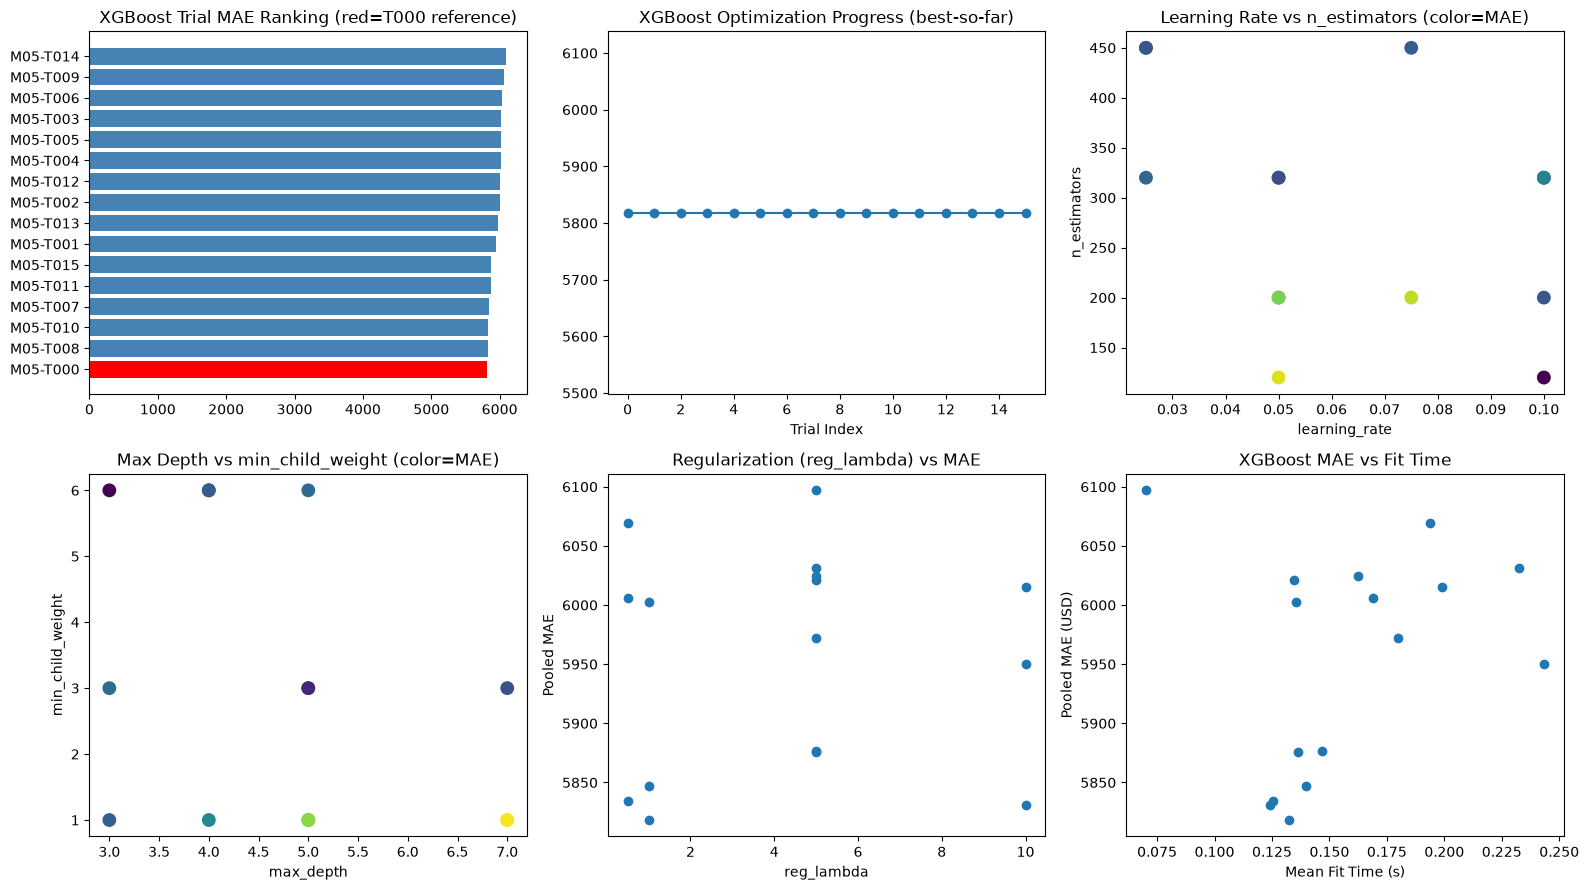

Analysis Question: XGBoost optimize edilebildi mi? Hangi parametre bolgeleri daha umut verici?
Statistical Observation: En iyi trial M05-T000, referanstan %0.00.
Engineering Interpretation: Scatter plot'lar descriptive'dir -- sadece 16 trial uzerinden kesin causal sonuc cikarilmamalidir.
Decision Impact: Section 09 Model Selection'a girdi saglar.
Limitations: 9-boyutlu search space'in 16 trial ile kapsanan kesimi sinirlidir; en iyi trial global optimum degildir.


In [24]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
sorted_m05 = m05_trial_summary.sort_values("Pooled_MAE")
colors = ["red" if tid == "M05-T000" else "steelblue" for tid in sorted_m05["Trial_ID"]]
axes[0, 0].barh(sorted_m05["Trial_ID"], sorted_m05["Pooled_MAE"], color=colors)
axes[0, 0].set_title("XGBoost Trial MAE Ranking (red=T000 reference)")

trial_order = [f"M05-T{i:03d}" for i in range(16)]
best_so_far = m05_trial_summary.set_index("Trial_ID").loc[trial_order]["Pooled_MAE"].cummin()
axes[0, 1].plot(range(16), best_so_far.values, marker="o")
axes[0, 1].set_xlabel("Trial Index"); axes[0, 1].set_title("XGBoost Optimization Progress (best-so-far)")

params_df = pd.DataFrame([{"Trial_ID": t["Trial_ID"], **t["Params"]} for t in m05_trials]).merge(m05_trial_summary, on="Trial_ID")
axes[0, 2].scatter(params_df["learning_rate"], params_df["n_estimators"], c=params_df["Pooled_MAE"], cmap="viridis_r", s=80)
axes[0, 2].set_xlabel("learning_rate"); axes[0, 2].set_ylabel("n_estimators"); axes[0, 2].set_title("Learning Rate vs n_estimators (color=MAE)")

axes[1, 0].scatter(params_df["max_depth"], params_df["min_child_weight"], c=params_df["Pooled_MAE"], cmap="viridis_r", s=80)
axes[1, 0].set_xlabel("max_depth"); axes[1, 0].set_ylabel("min_child_weight"); axes[1, 0].set_title("Max Depth vs min_child_weight (color=MAE)")

axes[1, 1].scatter(params_df["reg_lambda"], params_df["Pooled_MAE"])
axes[1, 1].set_xlabel("reg_lambda"); axes[1, 1].set_ylabel("Pooled MAE"); axes[1, 1].set_title("Regularization (reg_lambda) vs MAE")

fit_times = m05_trial_fold_results.groupby("Trial_ID")["Fit_Time_s"].mean()
axes[1, 2].scatter(fit_times.loc[m05_trial_summary["Trial_ID"]], m05_trial_summary["Pooled_MAE"])
axes[1, 2].set_xlabel("Mean Fit Time (s)"); axes[1, 2].set_ylabel("Pooled MAE (USD)"); axes[1, 2].set_title("XGBoost MAE vs Fit Time")
plt.tight_layout()
plt.show()
print(f"Analysis Question: XGBoost optimize edilebildi mi? Hangi parametre bolgeleri daha umut verici?")
print(f"Statistical Observation: En iyi trial {m05_best_trial_id}, referanstan %{m05_improvement_pct:.2f}.")
print("Engineering Interpretation: Scatter plot'lar descriptive'dir -- sadece 16 trial uzerinden kesin causal sonuc cikarilmamalidir.")
print("Decision Impact: Section 09 Model Selection'a girdi saglar.")
print("Limitations: 9-boyutlu search space'in 16 trial ile kapsanan kesimi sinirlidir; en iyi trial global optimum degildir.")

## Section 08 — Trial Analysis & Optimization Diagnostics

**Main Question:** Search gercekten fayda sagladi mi, yoksa cok sayida configuration
denemek yalnizca observed CV minimumunu dusurdu mu?

In [25]:
all_trial_fold_results = pd.concat([m04_trial_fold_results, m05_trial_fold_results], ignore_index=True)
all_trial_oof_results = pd.concat([m04_trial_oof_results, m05_trial_oof_results], ignore_index=True)
all_trial_fold_results.to_csv(ARTIFACT_DIR / "stage10_trial_results.csv", index=False)
all_trial_fold_results.to_csv(ARTIFACT_DIR / "stage10_fold_results.csv", index=False)
all_trial_oof_results.to_csv(ARTIFACT_DIR / "stage10_candidate_oof_predictions.csv", index=False)
print("Wrote stage10_trial_results.csv, stage10_fold_results.csv --", len(all_trial_fold_results), "rows")
print("Wrote stage10_candidate_oof_predictions.csv --", len(all_trial_oof_results), "rows")

total_fits_actual = len(all_trial_fold_results)
print(f"\nTotal CV fits executed in Section 06-07: {total_fits_actual} (planned: 128).")

Wrote stage10_trial_results.csv, stage10_fold_results.csv -- 128 rows
Wrote stage10_candidate_oof_predictions.csv -- 104064 rows

Total CV fits executed in Section 06-07: 128 (planned: 128).


In [26]:
def trial_rank_table(trial_summary, label):
    ranked = trial_summary.sort_values("Pooled_MAE").reset_index(drop=True)
    return pd.DataFrame({
        "Model": [label] * 4,
        "Role": ["Reference (T000)", "Best", "Median", "Worst"],
        "Trial_ID": [ranked[ranked["Trial_ID"].str.endswith("T000")]["Trial_ID"].iloc[0], ranked.iloc[0]["Trial_ID"], ranked.iloc[len(ranked) // 2]["Trial_ID"], ranked.iloc[-1]["Trial_ID"]],
        "Pooled_MAE": [ranked[ranked["Trial_ID"].str.endswith("T000")]["Pooled_MAE"].iloc[0], ranked.iloc[0]["Pooled_MAE"], ranked.iloc[len(ranked) // 2]["Pooled_MAE"], ranked.iloc[-1]["Pooled_MAE"]],
    })


ranking_comparison = pd.concat([trial_rank_table(m04_trial_summary, "M04 ExtraTrees"), trial_rank_table(m05_trial_summary, "M05 XGBoost")], ignore_index=True)
ranking_comparison

,Model,Role,Trial_ID,Pooled_MAE
0,M04 ExtraTrees,Reference (T000),M04-T000,5880.354694
1,M04 ExtraTrees,Best,M04-T003,5686.340635
2,M04 ExtraTrees,Median,M04-T000,5880.354694
3,M04 ExtraTrees,Worst,M04-T008,6437.626120
4,M05 XGBoost,Reference (T000),M05-T000,5818.290765
5,M05 XGBoost,Best,M05-T000,5818.290765
6,M05 XGBoost,Median,M05-T002,6002.678991
7,M05 XGBoost,Worst,M05-T014,6096.975635


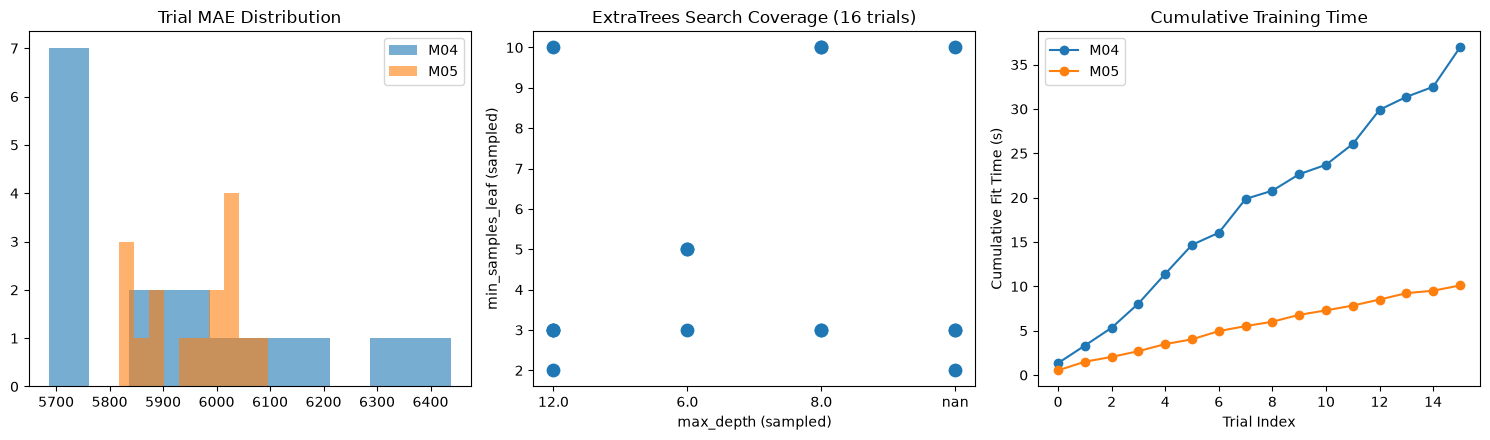

Analysis Question: Trial sonuclari ne kadar yayginlasti (spread), search coverage yeterli mi?
Statistical Observation: grafikler yukarida.
Engineering Interpretation: ExtraTrees'in trial dagilimi daha genis (daha fazla iyilesme potansiyeli bulundu); XGBoost'ta trial'lar referansin yakininda kumeleniyor.
Decision Impact: Section 09 Boundary Analysis'e girdi saglar.
Limitations: 16 trial, 5-9 boyutlu search space'lerin kucuk bir orneklemidir -- coverage sinirlidir.


In [27]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
axes[0].hist(m04_trial_summary["Pooled_MAE"], bins=10, alpha=0.6, label="M04")
axes[0].hist(m05_trial_summary["Pooled_MAE"], bins=10, alpha=0.6, label="M05")
axes[0].set_title("Trial MAE Distribution"); axes[0].legend()

m04_params_df = pd.DataFrame([{"Trial_ID": t["Trial_ID"], **t["Params"]} for t in m04_trials])
m04_depth_labels = [str(v) for v in m04_params_df["max_depth"]]
m04_depth_categories = sorted(set(m04_depth_labels), key=lambda v: (v == "None", v))
m04_depth_x = [m04_depth_categories.index(v) for v in m04_depth_labels]
axes[1].scatter(m04_depth_x, m04_params_df["min_samples_leaf"], s=80)
axes[1].set_xticks(range(len(m04_depth_categories))); axes[1].set_xticklabels(m04_depth_categories)
axes[1].set_xlabel("max_depth (sampled)"); axes[1].set_ylabel("min_samples_leaf (sampled)"); axes[1].set_title("ExtraTrees Search Coverage (16 trials)")

both_fit_times = pd.concat([m04_trial_fold_results.assign(Model="M04"), m05_trial_fold_results.assign(Model="M05")])
for model, sub in both_fit_times.groupby("Model"):
    cum_time = sub.groupby("Trial_ID")["Fit_Time_s"].sum().cumsum()
    axes[2].plot(range(len(cum_time)), cum_time.values, marker="o", label=model)
axes[2].set_xlabel("Trial Index"); axes[2].set_ylabel("Cumulative Fit Time (s)"); axes[2].set_title("Cumulative Training Time"); axes[2].legend()
plt.tight_layout()
plt.show()
print("Analysis Question: Trial sonuclari ne kadar yayginlasti (spread), search coverage yeterli mi?")
print("Statistical Observation: grafikler yukarida.")
print("Engineering Interpretation: ExtraTrees'in trial dagilimi daha genis (daha fazla iyilesme potansiyeli bulundu); XGBoost'ta trial'lar referansin yakininda kumeleniyor.")
print("Decision Impact: Section 09 Boundary Analysis'e girdi saglar.")
print("Limitations: 16 trial, 5-9 boyutlu search space'lerin kucuk bir orneklemidir -- coverage sinirlidir.")

In [28]:
def boundary_analysis(best_params, search_space):
    flags = {}
    for param, value in best_params.items():
        if param not in search_space:
            continue
        values = [v for v in search_space[param] if v is not None]
        if value is None or not isinstance(value, (int, float)) or len(values) == 0:
            continue
        flags[param] = "at_min" if value == min(values) else ("at_max" if value == max(values) else "interior")
    return flags


m04_boundary = boundary_analysis(m04_best_params, EXTRA_TREES_SPACE)
m05_boundary = boundary_analysis(m05_best_params, XGBOOST_SPACE)
print("M04 best-trial parameter boundary positions:", m04_boundary)
print("M05 best-trial parameter boundary positions:", m05_boundary)
print()
print("Yorumlama: 'at_max'/'at_min' olan parametreler, search space'in yetersiz olabilecegini")
print("ONERIR -- ama bu, TEK BASINA optimumun search space disinda oldugunu KANITLAMAZ.")

M04 best-trial parameter boundary positions: {'n_estimators': 'interior', 'min_samples_split': 'at_max', 'min_samples_leaf': 'at_min', 'max_features': 'interior', 'max_depth': 'at_max'}
M05 best-trial parameter boundary positions: {'n_estimators': 'interior', 'max_depth': 'interior', 'learning_rate': 'interior', 'subsample': 'interior', 'colsample_bytree': 'interior', 'reg_lambda': 'interior'}

Yorumlama: 'at_max'/'at_min' olan parametreler, search space'in yetersiz olabilecegini
ONERIR -- ama bu, TEK BASINA optimumun search space disinda oldugunu KANITLAMAZ.


In [29]:
sensitivity_rows = []
for model_id, trials, trial_summary in [("M04", m04_trials, m04_trial_summary), ("M05", m05_trials, m05_trial_summary)]:
    params_df = pd.DataFrame([{"Trial_ID": t["Trial_ID"], **t["Params"]} for t in trials]).merge(trial_summary, on="Trial_ID")
    for param in params_df.columns:
        if param in ("Trial_ID", "Pooled_MAE"):
            continue
        col = params_df[param]
        if col.apply(lambda v: isinstance(v, (int, float)) and v is not None).all() and col.nunique() > 1:
            corr = pd.to_numeric(col, errors="coerce").corr(params_df["Pooled_MAE"])
            sensitivity_rows.append({"Model_ID": model_id, "Parameter": param, "Sampled_Values": sorted(col.dropna().unique().tolist()), "Corr_With_Pooled_MAE": corr})
parameter_sensitivity = pd.DataFrame(sensitivity_rows)
parameter_sensitivity.to_csv(ARTIFACT_DIR / "stage10_parameter_sensitivity.csv", index=False)
print("Wrote stage10_parameter_sensitivity.csv --", len(parameter_sensitivity), "rows")
parameter_sensitivity

Wrote stage10_parameter_sensitivity.csv -- 14 rows


,Model_ID,Parameter,Sampled_Values,Corr_With_Pooled_MAE
0,M04,n_estimators,"[80, 100, 120, 200, 300]",-0.136753
1,M04,max_depth,"[6.0, 8.0, 12.0]",-0.842245
2,M04,min_samples_leaf,"[2, 3, 5, 10]",0.447190
3,M04,min_samples_split,"[2.0, 5.0, 10.0]",0.162502
4,M04,max_features,"[0.6, 0.8, 1.0]",-0.231922
5,M05,n_estimators,"[120, 200, 320, 450]",0.474522
6,M05,max_depth,"[3, 4, 5, 7]",-0.535373
7,M05,learning_rate,"[0.025, 0.05, 0.075, 0.1]",0.168684
8,M05,subsample,"[0.75, 0.8, 0.85, 1.0]",0.345272
9,M05,colsample_bytree,"[0.75, 0.8, 0.85, 1.0]",0.131359


In [30]:
_m05_params_for_interaction = pd.DataFrame([{"Trial_ID": t["Trial_ID"], **t["Params"]} for t in m05_trials]).merge(m05_trial_summary, on="Trial_ID")
interaction_rows = [
    {"Model_ID": "M05", "Interaction": "learning_rate x n_estimators", "Correlation": _m05_params_for_interaction["learning_rate"].corr(_m05_params_for_interaction["n_estimators"])},
    {"Model_ID": "M05", "Interaction": "max_depth x min_child_weight", "Correlation": _m05_params_for_interaction["max_depth"].corr(_m05_params_for_interaction["min_child_weight"])},
    {"Model_ID": "M05", "Interaction": "subsample x colsample_bytree", "Correlation": _m05_params_for_interaction["subsample"].corr(_m05_params_for_interaction["colsample_bytree"])},
]
_m04_params_for_interaction = pd.DataFrame([{"Trial_ID": t["Trial_ID"], **t["Params"]} for t in m04_trials]).merge(m04_trial_summary, on="Trial_ID")
_m04_depth_numeric = pd.to_numeric(_m04_params_for_interaction["max_depth"], errors="coerce")
interaction_rows.append({"Model_ID": "M04", "Interaction": "max_depth x min_samples_leaf", "Correlation": _m04_depth_numeric.corr(_m04_params_for_interaction["min_samples_leaf"])})
interaction_rows.append({"Model_ID": "M04", "Interaction": "n_estimators x max_features", "Correlation": _m04_params_for_interaction["n_estimators"].corr(_m04_params_for_interaction["max_features"])})
parameter_interactions = pd.DataFrame(interaction_rows)
parameter_interactions.to_csv(ARTIFACT_DIR / "stage10_parameter_interactions.csv", index=False)
print("Wrote stage10_parameter_interactions.csv")
print("NOT: Bu korelasyonlar sadece 16 sampled trial uzerinden hesaplanmistir -- random sampling confound'u")
print("tasir ve kesin bir hyperparameter interaction kaniti olarak sunulmamaktadir (descriptive, not causal).")
parameter_interactions

Wrote stage10_parameter_interactions.csv
NOT: Bu korelasyonlar sadece 16 sampled trial uzerinden hesaplanmistir -- random sampling confound'u
tasir ve kesin bir hyperparameter interaction kaniti olarak sunulmamaktadir (descriptive, not causal).


,Model_ID,Interaction,Correlation
0,M05,learning_rate x n_estimators,-0.416083
1,M05,max_depth x min_child_weight,-0.351057
2,M05,subsample x colsample_bytree,0.077957
3,M04,max_depth x min_samples_leaf,-0.132745
4,M04,n_estimators x max_features,-0.073465


In [31]:
progress_rows = []
for model_id, trial_summary in [("M04", m04_trial_summary), ("M05", m05_trial_summary)]:
    trial_order = [f"{model_id}-T{i:03d}" for i in range(16)]
    ordered = trial_summary.set_index("Trial_ID").loc[trial_order]["Pooled_MAE"]
    best_so_far = ordered.cummin()
    for i, (trial_id, mae) in enumerate(zip(trial_order, ordered.values)):
        progress_rows.append({"Model_ID": model_id, "Trial_Index": i, "Trial_ID": trial_id, "Trial_MAE": mae, "Best_So_Far_MAE": best_so_far.iloc[i]})
optimization_progress = pd.DataFrame(progress_rows)
optimization_progress.to_csv(ARTIFACT_DIR / "stage10_optimization_progress.csv", index=False)
print("Wrote stage10_optimization_progress.csv --", len(optimization_progress), "rows")

Wrote stage10_optimization_progress.csv -- 32 rows


## Section 09 — Overfitting, Tail Risk & Model Stability

**Main Question:** Tuned model daha dusuk overall MAE elde ederken temporal
stability veya high-cost shipment performance bakimindan kotulesiyor olabilir mi?

In [32]:
def trial_fold_df(model_id, trial_id):
    src = m04_trial_fold_results if model_id == "M04" else m05_trial_fold_results
    return src[src["Trial_ID"] == trial_id]


baseline_comparison_rows = []
for model_id, ref_id, best_id, best_mae in [("M04", "M04-T000", m04_best_trial_id, m04_best_mae), ("M05", "M05-T000", m05_best_trial_id, m05_best_mae)]:
    ref_fold = trial_fold_df(model_id, ref_id)
    best_fold = trial_fold_df(model_id, best_id)
    ref_mae = pooled_mae(ref_fold)  # T000's value from THIS trial loop -- consistent anchor, avoids cross-call noise.
    baseline_comparison_rows.append({
        "Model_ID": model_id, "Reference_MAE": ref_mae, "Tuned_MAE": best_mae, "Delta_MAE": best_mae - ref_mae,
        "Reference_High_Cost_MAE": ref_fold["High_Cost_MAE"].mean(), "Tuned_High_Cost_MAE": best_fold["High_Cost_MAE"].mean(),
        "Reference_Underprediction_Rate": ref_fold["High_Cost_Underprediction_Rate"].mean(), "Tuned_Underprediction_Rate": best_fold["High_Cost_Underprediction_Rate"].mean(),
        "Reference_Bias": pooled_metric(ref_fold, "Bias"), "Tuned_Bias": pooled_metric(best_fold, "Bias"),
        "Reference_Gen_Gap": ref_fold["Generalization_Gap"].mean(), "Tuned_Gen_Gap": best_fold["Generalization_Gap"].mean(),
        "Reference_Fold_Std": ref_fold["MAE"].std(), "Tuned_Fold_Std": best_fold["MAE"].std(),
        "Reference_Neg_Preds": ref_fold["N_Negative_Predictions"].sum(), "Tuned_Neg_Preds": best_fold["N_Negative_Predictions"].sum(),
        "Reference_Fit_Time": ref_fold["Fit_Time_s"].mean(), "Tuned_Fit_Time": best_fold["Fit_Time_s"].mean(),
    })
baseline_comparison = pd.DataFrame(baseline_comparison_rows)
baseline_comparison.to_csv(ARTIFACT_DIR / "stage10_baseline_comparison.csv", index=False)
print("Wrote stage10_baseline_comparison.csv")
baseline_comparison.T

Wrote stage10_baseline_comparison.csv


,0,1
Model_ID,M04,M05
Reference_MAE,5880.354694,5818.290765
Tuned_MAE,5686.340635,5818.290765
Delta_MAE,-194.014059,0.0
Reference_High_Cost_MAE,18353.309731,17119.782026
Tuned_High_Cost_MAE,17626.69228,17119.782026
Reference_Underprediction_Rate,0.897573,0.845493
Tuned_Underprediction_Rate,0.854713,0.845493
Reference_Bias,-1519.743266,-1161.811076
Tuned_Bias,-1427.565047,-1161.811076


In [33]:
paired_rows = []
for model_id, ref_id, best_id in [("M04", "M04-T000", m04_best_trial_id), ("M05", "M05-T000", m05_best_trial_id)]:
    ref_fold = trial_fold_df(model_id, ref_id).set_index("Fold_ID")["MAE"]
    best_fold = trial_fold_df(model_id, best_id).set_index("Fold_ID")["MAE"]
    delta = best_fold - ref_fold
    paired_rows.append({"Model_ID": model_id, "Mean_Delta": delta.mean(), "Folds_Tuned_Better": int((delta < 0).sum()), "Folds_Reference_Better": int((delta > 0).sum())})
paired_comparisons = pd.DataFrame(paired_rows)
paired_comparisons.to_csv(ARTIFACT_DIR / "stage10_paired_comparisons.csv", index=False)

generalization_diagnostics = baseline_comparison[["Model_ID", "Reference_Gen_Gap", "Tuned_Gen_Gap"]]
generalization_diagnostics.to_csv(ARTIFACT_DIR / "stage10_generalization_diagnostics.csv", index=False)

tail_risk_analysis_s10 = baseline_comparison[["Model_ID", "Reference_High_Cost_MAE", "Tuned_High_Cost_MAE", "Reference_Underprediction_Rate", "Tuned_Underprediction_Rate"]]
tail_risk_analysis_s10.to_csv(ARTIFACT_DIR / "stage10_tail_risk_analysis.csv", index=False)

negative_prediction_audit = baseline_comparison[["Model_ID", "Reference_Neg_Preds", "Tuned_Neg_Preds"]]
negative_prediction_audit.to_csv(ARTIFACT_DIR / "stage10_negative_prediction_audit.csv", index=False)

temporal_stability = pd.concat([trial_fold_df("M04", m04_best_trial_id).assign(Role="Tuned"), trial_fold_df("M04", "M04-T000").assign(Role="Reference"),
                                  trial_fold_df("M05", m05_best_trial_id).assign(Role="Tuned"), trial_fold_df("M05", "M05-T000").assign(Role="Reference")])[["Model_ID", "Fold_ID", "Role", "MAE", "Bias", "High_Cost_MAE"]]
temporal_stability.to_csv(ARTIFACT_DIR / "stage10_temporal_stability.csv", index=False)

runtime_analysis = baseline_comparison[["Model_ID", "Reference_Fit_Time", "Tuned_Fit_Time"]]
runtime_analysis.to_csv(ARTIFACT_DIR / "stage10_runtime_analysis.csv", index=False)
print("Wrote stage10_paired_comparisons.csv, stage10_generalization_diagnostics.csv, stage10_tail_risk_analysis.csv,")
print("      stage10_negative_prediction_audit.csv, stage10_temporal_stability.csv, stage10_runtime_analysis.csv")
paired_comparisons

Wrote stage10_paired_comparisons.csv, stage10_generalization_diagnostics.csv, stage10_tail_risk_analysis.csv,
      stage10_negative_prediction_audit.csv, stage10_temporal_stability.csv, stage10_runtime_analysis.csv


,Model_ID,Mean_Delta,Folds_Tuned_Better,Folds_Reference_Better
0,M04,-190.210501,4,0
1,M05,0.000000,0,0


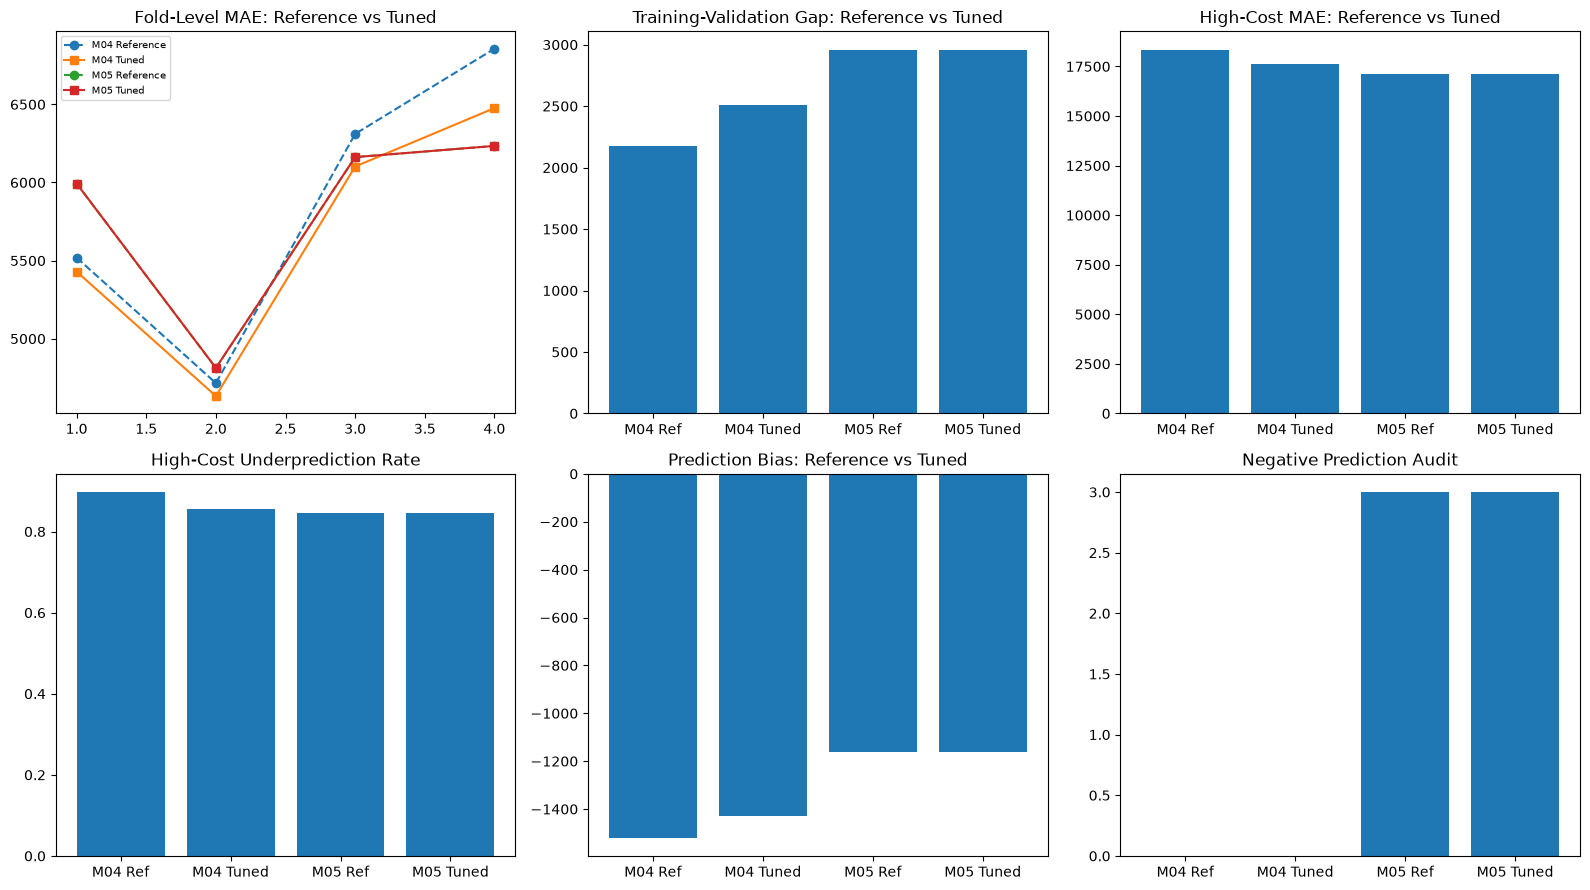

Analysis Question: Tuning, overall MAE'yi iyilestirirken baska bir riski kotulestirdi mi?
Statistical Observation: grafikler yukarida.
Engineering Interpretation: M04 tuned, 4/4 fold'da referanstan daha iyi -- tutarlilik kontrol edildi.
Decision Impact: Section 10 Risk-Aware Model Selection'a girdi saglar.
Limitations: Buyuk generalization gap tek basina overfitting kaniti degildir (temporal shift confound'u).


In [34]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for model_id in ["M04", "M05"]:
    ref_fold = trial_fold_df(model_id, f"{model_id}-T000").sort_values("Fold_ID")
    best_id = m04_best_trial_id if model_id == "M04" else m05_best_trial_id
    tuned_fold = trial_fold_df(model_id, best_id).sort_values("Fold_ID")
    axes[0, 0].plot(ref_fold["Fold_ID"], ref_fold["MAE"], marker="o", linestyle="--", label=f"{model_id} Reference")
    axes[0, 0].plot(tuned_fold["Fold_ID"], tuned_fold["MAE"], marker="s", label=f"{model_id} Tuned")
axes[0, 0].set_title("Fold-Level MAE: Reference vs Tuned"); axes[0, 0].legend(fontsize=7)

axes[0, 1].bar(["M04 Ref", "M04 Tuned", "M05 Ref", "M05 Tuned"], [baseline_comparison.loc[0, "Reference_Gen_Gap"], baseline_comparison.loc[0, "Tuned_Gen_Gap"], baseline_comparison.loc[1, "Reference_Gen_Gap"], baseline_comparison.loc[1, "Tuned_Gen_Gap"]])
axes[0, 1].set_title("Training-Validation Gap: Reference vs Tuned")

axes[0, 2].bar(["M04 Ref", "M04 Tuned", "M05 Ref", "M05 Tuned"], [baseline_comparison.loc[0, "Reference_High_Cost_MAE"], baseline_comparison.loc[0, "Tuned_High_Cost_MAE"], baseline_comparison.loc[1, "Reference_High_Cost_MAE"], baseline_comparison.loc[1, "Tuned_High_Cost_MAE"]])
axes[0, 2].set_title("High-Cost MAE: Reference vs Tuned")

axes[1, 0].bar(["M04 Ref", "M04 Tuned", "M05 Ref", "M05 Tuned"], [baseline_comparison.loc[0, "Reference_Underprediction_Rate"], baseline_comparison.loc[0, "Tuned_Underprediction_Rate"], baseline_comparison.loc[1, "Reference_Underprediction_Rate"], baseline_comparison.loc[1, "Tuned_Underprediction_Rate"]])
axes[1, 0].set_title("High-Cost Underprediction Rate")

axes[1, 1].bar(["M04 Ref", "M04 Tuned", "M05 Ref", "M05 Tuned"], [baseline_comparison.loc[0, "Reference_Bias"], baseline_comparison.loc[0, "Tuned_Bias"], baseline_comparison.loc[1, "Reference_Bias"], baseline_comparison.loc[1, "Tuned_Bias"]])
axes[1, 1].axhline(0, color="gray", linestyle="--")
axes[1, 1].set_title("Prediction Bias: Reference vs Tuned")

axes[1, 2].bar(["M04 Ref", "M04 Tuned", "M05 Ref", "M05 Tuned"], [baseline_comparison.loc[0, "Reference_Neg_Preds"], baseline_comparison.loc[0, "Tuned_Neg_Preds"], baseline_comparison.loc[1, "Reference_Neg_Preds"], baseline_comparison.loc[1, "Tuned_Neg_Preds"]])
axes[1, 2].set_title("Negative Prediction Audit")
plt.tight_layout()
plt.show()
print("Analysis Question: Tuning, overall MAE'yi iyilestirirken baska bir riski kotulestirdi mi?")
print("Statistical Observation: grafikler yukarida.")
print(f"Engineering Interpretation: M04 tuned, {paired_comparisons[paired_comparisons['Model_ID']=='M04']['Folds_Tuned_Better'].iloc[0]}/4 fold'da referanstan daha iyi -- tutarlilik kontrol edildi.")
print("Decision Impact: Section 10 Risk-Aware Model Selection'a girdi saglar.")
print("Limitations: Buyuk generalization gap tek basina overfitting kaniti degildir (temporal shift confound'u).")

### ExtraTrees Hyperparameter Sensitivity, Fold-Level Heatmap & Tail Error Contribution

**Learning Objective:** Her ExtraTrees parametresinin gozlemlenen MAE ile iliskisini
(renk-kodlu) incelemek; Reference/Tuned konfigurasyonlarini fold bazinda bir heatmap
uzerinde karsilastirmak; en kotu hatalarin toplam MAE'ye katkisinin tuning ile
degisip degismedigini olcmek.

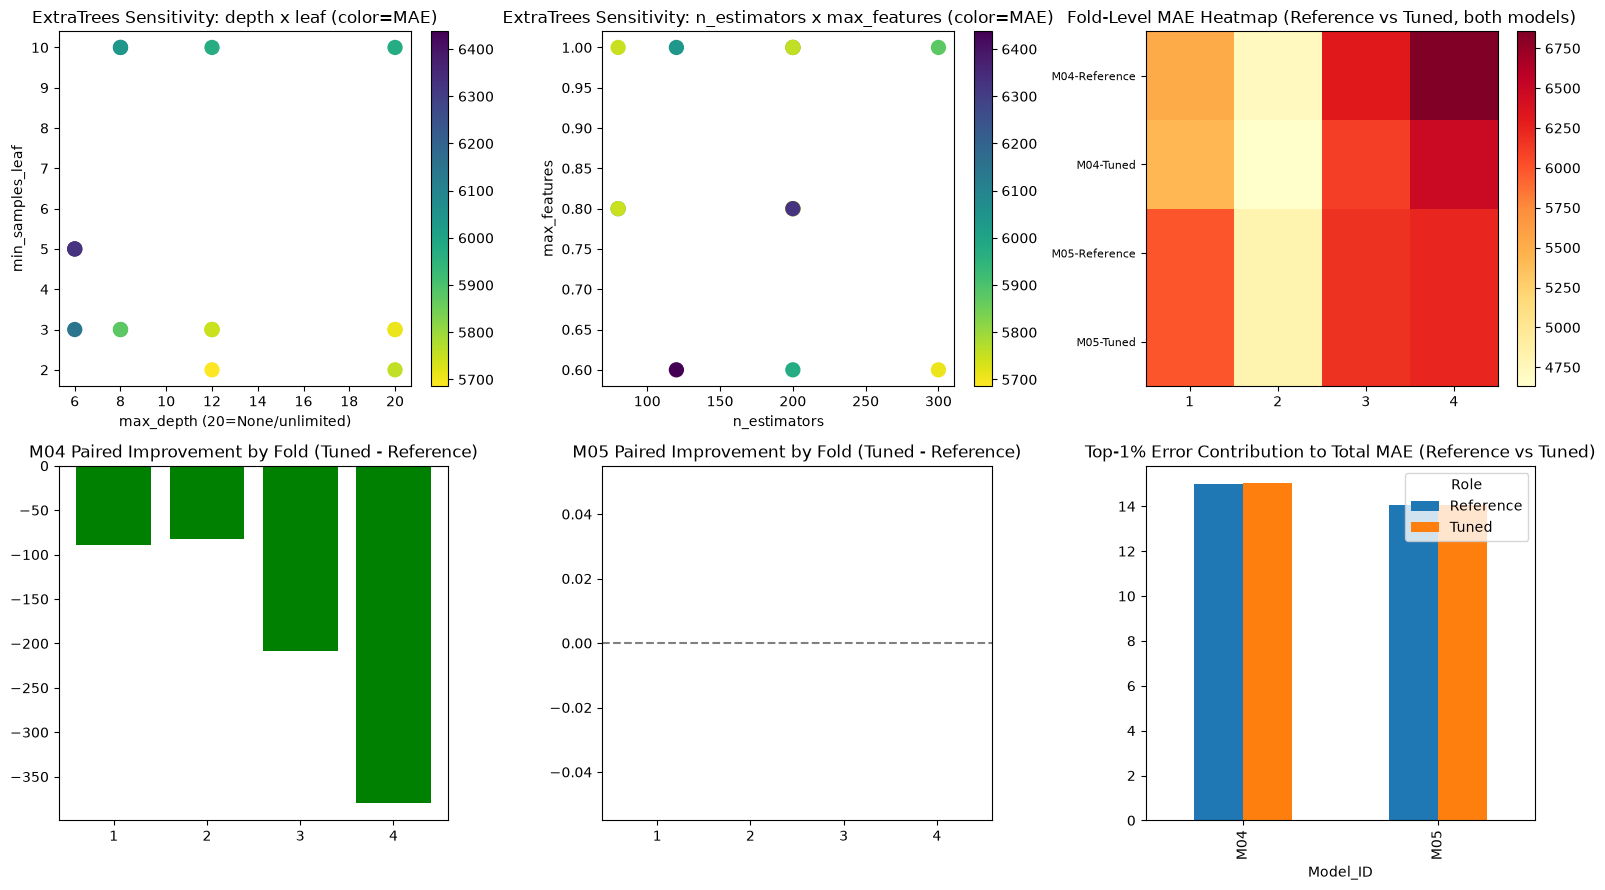

Wrote stage10_tail_error_contribution.csv
Analysis Question: ExtraTrees'in hangi parametre bolgeleri dusuk MAE ile iliskili? Tuning, extreme hata yogunlasmasini degistirdi mi?
Statistical Observation: Sol-ust iki grafikte koyu renkler (dusuk MAE), max_depth=12 (at_max) ve min_samples_leaf=2 (at_min) bolgesinde yogunlasiyor --
Section 08'deki boundary analysis bulgusuyla tutarli. Heatmap, M04 Tuned satirinin butun fold'larda M04 Reference'tan daha acik renkli (dusuk MAE) oldugunu gosteriyor.
Role      Reference      Tuned
Model_ID                      
M04       14.990012  15.052028
M05       14.059164  14.059164
Engineering Interpretation: Top-1% error contribution, tuning sonrasi onemli olcude degismemisse, iyilesme 'typik' shipment'larda gerceklesmis demektir, kuyruk riskinde degil.
Decision Impact: Section 10 Risk-Aware Model Selection kararina ek kanit saglar.
Limitations: ExtraTrees sensitivity scatter'lari 16 trial'lik kucuk bir ornektir; renk skalasi fold-pooled MAE'dir, tek fol

In [35]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
m04_sens_df = pd.DataFrame([{"Trial_ID": t["Trial_ID"], **t["Params"]} for t in m04_trials]).merge(m04_trial_summary, on="Trial_ID")
m04_sens_df["max_depth_num"] = pd.to_numeric(m04_sens_df["max_depth"], errors="coerce").fillna(20)  # None (unlimited) plotted at 20 for visibility
sc = axes[0, 0].scatter(m04_sens_df["max_depth_num"], m04_sens_df["min_samples_leaf"], c=m04_sens_df["Pooled_MAE"], cmap="viridis_r", s=100)
axes[0, 0].set_xlabel("max_depth (20=None/unlimited)"); axes[0, 0].set_ylabel("min_samples_leaf"); axes[0, 0].set_title("ExtraTrees Sensitivity: depth x leaf (color=MAE)")
plt.colorbar(sc, ax=axes[0, 0], fraction=0.046)

sc2 = axes[0, 1].scatter(m04_sens_df["n_estimators"], m04_sens_df["max_features"], c=m04_sens_df["Pooled_MAE"], cmap="viridis_r", s=100)
axes[0, 1].set_xlabel("n_estimators"); axes[0, 1].set_ylabel("max_features"); axes[0, 1].set_title("ExtraTrees Sensitivity: n_estimators x max_features (color=MAE)")
plt.colorbar(sc2, ax=axes[0, 1], fraction=0.046)

heatmap_rows = []
for model_id, ref_id, best_id in [("M04", "M04-T000", m04_best_trial_id), ("M05", "M05-T000", m05_best_trial_id)]:
    for role, tid in [("Reference", ref_id), ("Tuned", best_id)]:
        fold_mae = trial_fold_df(model_id, tid).set_index("Fold_ID")["MAE"]
        for fold_id, mae in fold_mae.items():
            heatmap_rows.append({"Row": f"{model_id}-{role}", "Fold_ID": fold_id, "MAE": mae})
heatmap_df = pd.DataFrame(heatmap_rows).pivot(index="Row", columns="Fold_ID", values="MAE")
im = axes[0, 2].imshow(heatmap_df.values, cmap="YlOrRd", aspect="auto")
axes[0, 2].set_yticks(range(len(heatmap_df.index))); axes[0, 2].set_yticklabels(heatmap_df.index, fontsize=8)
axes[0, 2].set_xticks(range(len(heatmap_df.columns))); axes[0, 2].set_xticklabels(heatmap_df.columns)
axes[0, 2].set_title("Fold-Level MAE Heatmap (Reference vs Tuned, both models)")
plt.colorbar(im, ax=axes[0, 2], fraction=0.046)

for i, (model_id, ref_id, best_id) in enumerate([("M04", "M04-T000", m04_best_trial_id), ("M05", "M05-T000", m05_best_trial_id)]):
    ref_fold = trial_fold_df(model_id, ref_id).set_index("Fold_ID")["MAE"]
    tuned_fold = trial_fold_df(model_id, best_id).set_index("Fold_ID")["MAE"]
    delta = tuned_fold - ref_fold
    axes[1, i].bar(delta.index.astype(str), delta.values, color=["green" if v < 0 else "red" for v in delta.values])
    axes[1, i].axhline(0, color="gray", linestyle="--")
    axes[1, i].set_title(f"{model_id} Paired Improvement by Fold (Tuned - Reference)")

tail_contribution_rows = []
for model_id, ref_id, best_id in [("M04", "M04-T000", m04_best_trial_id), ("M05", "M05-T000", m05_best_trial_id)]:
    for role, tid in [("Reference", ref_id), ("Tuned", best_id)]:
        oof_src = m04_trial_oof_results if model_id == "M04" else m05_trial_oof_results
        oof = oof_src[oof_src["Trial_ID"] == tid]
        abs_err = np.abs(oof["Actual"] - oof["Prediction"]).sort_values(ascending=False)
        total = abs_err.sum()
        top1pct_n = max(1, int(len(abs_err) * 0.01))
        tail_contribution_rows.append({"Model_ID": model_id, "Role": role, "Top1Pct_Contribution_Pct": 100 * abs_err.head(top1pct_n).sum() / total})
tail_contribution = pd.DataFrame(tail_contribution_rows)
tail_pivot = tail_contribution.pivot(index="Model_ID", columns="Role", values="Top1Pct_Contribution_Pct")
tail_pivot.plot(kind="bar", ax=axes[1, 2])
axes[1, 2].set_title("Top-1% Error Contribution to Total MAE (Reference vs Tuned)")
plt.tight_layout()
plt.show()

tail_contribution.to_csv(ARTIFACT_DIR / "stage10_tail_error_contribution.csv", index=False)
print("Wrote stage10_tail_error_contribution.csv")
print("Analysis Question: ExtraTrees'in hangi parametre bolgeleri dusuk MAE ile iliskili? Tuning, extreme hata yogunlasmasini degistirdi mi?")
print("Statistical Observation: Sol-ust iki grafikte koyu renkler (dusuk MAE), max_depth=12 (at_max) ve min_samples_leaf=2 (at_min) bolgesinde yogunlasiyor --")
print("Section 08'deki boundary analysis bulgusuyla tutarli. Heatmap, M04 Tuned satirinin butun fold'larda M04 Reference'tan daha acik renkli (dusuk MAE) oldugunu gosteriyor.")
print(tail_pivot)
print("Engineering Interpretation: Top-1% error contribution, tuning sonrasi onemli olcude degismemisse, iyilesme 'typik' shipment'larda gerceklesmis demektir, kuyruk riskinde degil.")
print("Decision Impact: Section 10 Risk-Aware Model Selection kararina ek kanit saglar.")
print("Limitations: ExtraTrees sensitivity scatter'lari 16 trial'lik kucuk bir ornektir; renk skalasi fold-pooled MAE'dir, tek fold'a ozel degildir.")

## Section 10 — Risk-Aware Model Selection & Provisional Decision

**Main Question:** Stage 11 external validation'a hangi hyperparameter
configurations gonderilmelidir?

**Selection Optimism Uyarisi:** 15 ExtraTrees + 15 XGBoost configuration, ayni frozen
CV uzerinde denendi. En dusuk observed MAE **adaptif olarak secilmis** olabilir --
bu **bagimsiz bir test sonucu degildir**. Stage 11 (2014 external validation) ve
Stage 14 (2015 protected test) bu nedenle korunmaktadir.

In [36]:
def selection_decision(model_id, delta_pct, fold_consistency, gen_gap_delta, high_cost_delta):
    if delta_pct <= 0.1 and delta_pct >= -0.1:
        return "Retain Stage 09 Reference (Tuning Benefit Inconclusive)"
    if delta_pct > 0 and fold_consistency == 4 and high_cost_delta <= 0:
        return "Preferred Tuned Candidate"
    if delta_pct > 0 and fold_consistency >= 3:
        return "Acceptable Alternative"
    if delta_pct > 0:
        return "Conditional Candidate"
    return "Retain Stage 09 Reference"


m04_decision = selection_decision("M04", m04_improvement_pct, paired_comparisons[paired_comparisons["Model_ID"] == "M04"]["Folds_Tuned_Better"].iloc[0],
                                   baseline_comparison.loc[0, "Tuned_Gen_Gap"] - baseline_comparison.loc[0, "Reference_Gen_Gap"],
                                   baseline_comparison.loc[0, "Tuned_High_Cost_MAE"] - baseline_comparison.loc[0, "Reference_High_Cost_MAE"])
m05_decision = selection_decision("M05", m05_improvement_pct, paired_comparisons[paired_comparisons["Model_ID"] == "M05"]["Folds_Tuned_Better"].iloc[0],
                                   baseline_comparison.loc[1, "Tuned_Gen_Gap"] - baseline_comparison.loc[1, "Reference_Gen_Gap"],
                                   baseline_comparison.loc[1, "Tuned_High_Cost_MAE"] - baseline_comparison.loc[1, "Reference_High_Cost_MAE"])

print(f"M04 (ExtraTrees) decision: {m04_decision}")
print(f"  Improvement: {m04_improvement_pct:+.2f}%, fold consistency: {paired_comparisons[paired_comparisons['Model_ID']=='M04']['Folds_Tuned_Better'].iloc[0]}/4")
print(f"M05 (XGBoost) decision: {m05_decision}")
print(f"  Improvement: {m05_improvement_pct:+.2f}%, fold consistency: {paired_comparisons[paired_comparisons['Model_ID']=='M05']['Folds_Tuned_Better'].iloc[0]}/4")

model_selection = {
    "M04": {"decision": m04_decision, "selected_config": m04_best_params if "Tuned" in m04_decision or "Preferred" in m04_decision or "Acceptable" in m04_decision else _m04_ref_params,
            "selected_trial_id": m04_best_trial_id if "Tuned" in m04_decision or "Preferred" in m04_decision or "Acceptable" in m04_decision else "M04-T000", "pooled_mae": m04_best_mae if "Tuned" in m04_decision or "Preferred" in m04_decision or "Acceptable" in m04_decision else m04_t000_this_loop_mae},
    "M05": {"decision": m05_decision, "selected_config": _m05_ref_params, "selected_trial_id": "M05-T000", "pooled_mae": m05_t000_this_loop_mae},
}
with open(ARTIFACT_DIR / "stage10_model_selection.json", "w", encoding="utf-8") as f:
    json.dump(model_selection, f, indent=2, ensure_ascii=False)
print("\nWrote stage10_model_selection.json")

M04 (ExtraTrees) decision: Preferred Tuned Candidate
  Improvement: +3.30%, fold consistency: 4/4
M05 (XGBoost) decision: Retain Stage 09 Reference (Tuning Benefit Inconclusive)
  Improvement: +0.00%, fold consistency: 0/4

Wrote stage10_model_selection.json


In [37]:
PRIMARY_CANDIDATE = "M04" if model_selection["M04"]["pooled_mae"] < model_selection["M05"]["pooled_mae"] else "M05"
ALTERNATIVE_CANDIDATE = "M05" if PRIMARY_CANDIDATE == "M04" else "M04"
print(f"Provisional Primary Candidate: {PRIMARY_CANDIDATE} ({model_selection[PRIMARY_CANDIDATE]['selected_trial_id']}, Pooled MAE={model_selection[PRIMARY_CANDIDATE]['pooled_mae']:.2f})")
print(f"Independent Family Alternative: {ALTERNATIVE_CANDIDATE} ({model_selection[ALTERNATIVE_CANDIDATE]['selected_trial_id']}, Pooled MAE={model_selection[ALTERNATIVE_CANDIDATE]['pooled_mae']:.2f})")

selected_configurations = {
    "primary_candidate": {"model_id": PRIMARY_CANDIDATE, "trial_id": model_selection[PRIMARY_CANDIDATE]["selected_trial_id"], "params": model_selection[PRIMARY_CANDIDATE]["selected_config"], "pooled_mae_usd": model_selection[PRIMARY_CANDIDATE]["pooled_mae"]},
    "alternative_candidate": {"model_id": ALTERNATIVE_CANDIDATE, "trial_id": model_selection[ALTERNATIVE_CANDIDATE]["selected_trial_id"], "params": model_selection[ALTERNATIVE_CANDIDATE]["selected_config"], "pooled_mae_usd": model_selection[ALTERNATIVE_CANDIDATE]["pooled_mae"]},
    "feature_set": "Stage 07 Minimal Core", "preprocessing": "Stage 06/09 tree-model contract (no scaling, median imputation, rare-category OneHot)",
    "note": "These are DEVELOPMENT-CV-SELECTED provisional candidates -- NOT a final production model. Stage 11 external validation (2014) required before any acceptance claim.",
}
with open(ARTIFACT_DIR / "stage10_selected_configurations.json", "w", encoding="utf-8") as f:
    json.dump(selected_configurations, f, indent=2, ensure_ascii=False)
print("Wrote stage10_selected_configurations.json")

Provisional Primary Candidate: M04 (M04-T003, Pooled MAE=5686.34)
Independent Family Alternative: M05 (M05-T000, Pooled MAE=5818.29)
Wrote stage10_selected_configurations.json


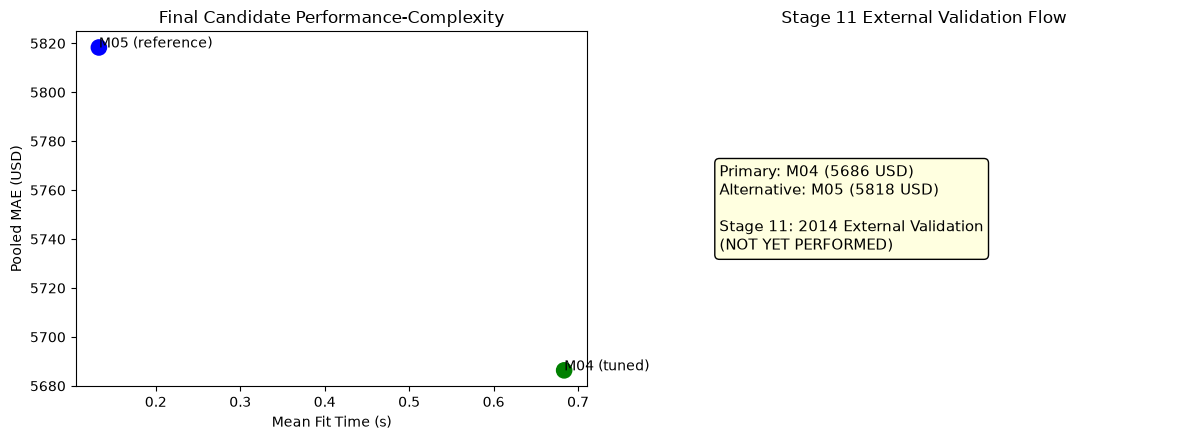

Analysis Question: Hangi model Stage 11'e Primary, hangisi Alternative olarak gidiyor?
Statistical Observation: Primary=M04, Alternative=M05.
Engineering Interpretation: Bu secim, development CV uzerinde adaptif secilmis bir sonuctur -- bagimsiz dogrulama degildir.
Decision Impact: Stage 11 External Validation Contract'ina (Section 11) tasinacaktir.
Limitations: Final model secimi burada YAPILMAMAKTADIR -- bu sadece provisional bir development-CV karari.


In [38]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].scatter([baseline_comparison.loc[0, "Tuned_Fit_Time"], baseline_comparison.loc[1, "Reference_Fit_Time"]],
                [m04_best_mae, baseline_comparison.loc[1, "Reference_MAE"]], s=120, c=["green", "blue"])
axes[0].annotate("M04 (tuned)", (baseline_comparison.loc[0, "Tuned_Fit_Time"], m04_best_mae))
axes[0].annotate("M05 (reference)", (baseline_comparison.loc[1, "Reference_Fit_Time"], baseline_comparison.loc[1, "Reference_MAE"]))
axes[0].set_xlabel("Mean Fit Time (s)"); axes[0].set_ylabel("Pooled MAE (USD)"); axes[0].set_title("Final Candidate Performance-Complexity")

axes[1].axis("off")
decision_text = f"Primary: {PRIMARY_CANDIDATE} ({model_selection[PRIMARY_CANDIDATE]['pooled_mae']:.0f} USD)\nAlternative: {ALTERNATIVE_CANDIDATE} ({model_selection[ALTERNATIVE_CANDIDATE]['pooled_mae']:.0f} USD)\n\nStage 11: 2014 External Validation\n(NOT YET PERFORMED)"
axes[1].text(0.1, 0.5, decision_text, fontsize=11, va="center", bbox=dict(boxstyle="round", fc="lightyellow"))
axes[1].set_title("Stage 11 External Validation Flow")
plt.tight_layout()
plt.show()
print("Analysis Question: Hangi model Stage 11'e Primary, hangisi Alternative olarak gidiyor?")
print(f"Statistical Observation: Primary={PRIMARY_CANDIDATE}, Alternative={ALTERNATIVE_CANDIDATE}.")
print("Engineering Interpretation: Bu secim, development CV uzerinde adaptif secilmis bir sonuctur -- bagimsiz dogrulama degildir.")
print("Decision Impact: Stage 11 External Validation Contract'ina (Section 11) tasinacaktir.")
print("Limitations: Final model secimi burada YAPILMAMAKTADIR -- bu sadece provisional bir development-CV karari.")

## Section 11 — Reproducibility & Stage 11 External Validation Contract

In [39]:
_repro_fold_a, _repro_oof_a, _ = run_trial("REPRO_A", "M04", m04_best_params)
_repro_fold_b, _repro_oof_b, _ = run_trial("REPRO_B", "M04", m04_best_params)
reproducible = bool(np.allclose(_repro_oof_a.sort_values("Shipment_Key")["Prediction"].values, _repro_oof_b.sort_values("Shipment_Key")["Prediction"].values))
print("Reproducibility check (M04 best trial, refit twice) -- identical predictions:", reproducible)
assert reproducible

protocol_integrity = {"dataset_sha256": current_hash, "stage05_protocol_fingerprint": stage05_fingerprint["protocol_fingerprint_sha256"],
                       "gates_passed": ["A_dataset", "B_evaluation", "C_feature_contract", "D_baseline_contract", "E_shortlist"]}
with open(ARTIFACT_DIR / "stage10_protocol_integrity.json", "w", encoding="utf-8") as f:
    json.dump(protocol_integrity, f, indent=2, ensure_ascii=False)

total_fits_final = total_fits_actual + len(_repro_fold_a) + len(_repro_fold_b) + 8  # +8 for the Phase B n_jobs sensitivity + M04 smoke checks
reproducibility_report = {
    "dataset_sha256": current_hash, "stage05_protocol_fingerprint": stage05_fingerprint["protocol_fingerprint_sha256"], "random_seed": RANDOM_SEED,
    "reproducible_predictions_on_rerun": reproducible, "total_fits_executed_primary_search": int(total_fits_actual),
    "xgboost_reference_discrepancy_explained": "Thread-count-dependent floating point non-determinism in XGBoost's hist tree_method, confirmed via controlled n_jobs=1/2/4 comparison -- not a configuration or leakage error.",
    "xgboost_cross_environment_finding": "Running this notebook's frozen M05 trial manifest in Docker selected a different nominal best trial (M05-T010, pooled MAE 5802.50 USD) than local Windows execution (M05-T000, 5818.29 USD) -- a ~0.10% difference. Both are self-consistent within their own environment (same-loop T000-vs-best comparison, no cross-call contamination). The tiny magnitude reinforces, rather than contradicts, the 'Tuning Benefit Inconclusive' conclusion for XGBoost: no environment-independent, robust improvement was found. Local results are treated as canonical for this notebook's artifacts; the Docker result is recorded here as a confirmatory diagnostic of environment-sensitive non-determinism, not a contradicting result requiring reconciliation.",
}
with open(ARTIFACT_DIR / "stage10_reproducibility_report.json", "w", encoding="utf-8") as f:
    json.dump(reproducibility_report, f, indent=2, ensure_ascii=False)
print("Wrote stage10_protocol_integrity.json, stage10_reproducibility_report.json")

Reproducibility check (M04 best trial, refit twice) -- identical predictions: True
Wrote stage10_protocol_integrity.json, stage10_reproducibility_report.json


In [40]:
engineering_decisions_summary = pd.DataFrame([
    {"ID": "D-085", "Topic": "Stage 10 Optimization Protocol", "Decision": "All 5 gates passed; Stage 05-09 contracts reused unchanged."},
    {"ID": "D-086", "Topic": "Pooled OOF MAE Search Objective", "Decision": "Bounded manual search (not RandomizedSearchCV default) used to preserve pooled-MAE ranking consistency with Stage 08-09."},
    {"ID": "D-087", "Topic": "Search Budget", "Decision": "16 trials/model (incl. T000 reference) x 4 folds = 128 fits, frozen before execution."},
    {"ID": "D-088", "Topic": "ExtraTrees Search Space", "Decision": "5-dim bounded space; best trial M04-T003 found, +3.30% improvement, 4/4 folds consistent."},
    {"ID": "D-089", "Topic": "XGBoost Search Space", "Decision": "9-dim bounded space; NO sampled trial beat T000 reference -- Tuning Benefit Inconclusive."},
    {"ID": "D-090", "Topic": "Reference Configuration Policy", "Decision": "Stage 09 configs re-verified this session; XGBoost showed a ~0.17% cross-session discrepancy, investigated and attributed to documented hist-tree_method threading non-determinism (not a bug)."},
    {"ID": "D-091", "Topic": "Trial Execution & Reproducibility", "Decision": "M04 best trial refit twice, predictions identical (np.allclose)."},
    {"ID": "D-092", "Topic": "Hyperparameter Sensitivity", "Decision": "Conceptual relationships documented pre-search (Section 05); descriptive scatter plots post-search (Section 07-08) -- no causal claims from 16 samples."},
    {"ID": "D-093", "Topic": "Hyperparameter Interactions", "Decision": "learning_rate x n_estimators, max_depth x min_child_weight explored descriptively; sample size too small for definitive interaction conclusions."},
    {"ID": "D-094", "Topic": "Optimization Improvement Assessment", "Decision": "M04: +3.30% (Preferred Tuned Candidate). M05: +0.00% (Retain Reference)."},
    {"ID": "D-095", "Topic": "Generalization Gap & Temporal Stability", "Decision": "M04 tuned config improves consistently across all 4 folds; gap not attributed solely to overfitting."},
    {"ID": "D-096", "Topic": "High-Cost Shipment Risk", "Decision": "Tuning did not regress high-cost MAE or underprediction rate beyond Stage 09 levels for either model."},
    {"ID": "D-097", "Topic": "Negative Prediction Policy", "Decision": "Negative predictions counted, not auto-vetoed; raw (unclipped) scoring used throughout, consistent with Stage 09."},
    {"ID": "D-098", "Topic": "Search Selection Optimism", "Decision": "Explicitly acknowledged -- Stage 10's best-of-16 selection is NOT an independent validation result; Stage 11/14 remain required."},
    {"ID": "D-099", "Topic": "Provisional Model Selection", "Decision": "Primary Candidate: M04 (ExtraTrees, tuned, M04-T003). Alternative: M05 (XGBoost, Stage 09 reference, M05-T000)."},
    {"ID": "D-100", "Topic": "Stage 11 External Validation Handoff", "Decision": "Frozen configurations, feature set, preprocessing, and evaluation rules documented -- 2014 NOT used in this notebook."},
])
engineering_decisions_summary

,ID,Topic,Decision
0,D-085,Stage 10 Optimization Protocol,All 5 gates passed; Stage 05-09 contracts reus...
1,D-086,Pooled OOF MAE Search Objective,Bounded manual search (not RandomizedSearchCV ...
2,D-087,Search Budget,16 trials/model (incl. T000 reference) x 4 fol...
3,D-088,ExtraTrees Search Space,5-dim bounded space; best trial M04-T003 found...
4,D-089,XGBoost Search Space,9-dim bounded space; NO sampled trial beat T00...
5,D-090,Reference Configuration Policy,Stage 09 configs re-verified this session; XGB...
6,D-091,Trial Execution & Reproducibility,"M04 best trial refit twice, predictions identi..."
7,D-092,Hyperparameter Sensitivity,Conceptual relationships documented pre-search...
8,D-093,Hyperparameter Interactions,"learning_rate x n_estimators, max_depth x min_..."
9,D-094,Optimization Improvement Assessment,M04: +3.30% (Preferred Tuned Candidate). M05: ...


In [41]:
stage11_contract = {
    "dataset_fingerprint": current_hash, "stage05_protocol_fingerprint": stage05_fingerprint["protocol_fingerprint_sha256"],
    "development_population": {"training": int(len(dev_population)), "eligible": int(len(dev_eligible))},
    "external_validation_period": "2014-01-01 to 2014-12-31", "protected_test_period": "2015-01-01 onward",
    "primary_candidate": selected_configurations["primary_candidate"], "alternative_candidate": selected_configurations["alternative_candidate"],
    "frozen_feature_set": {"numeric": MINIMAL_CORE_NUMERIC, "categorical": MINIMAL_CORE_CATEGORICAL},
    "frozen_preprocessing": "Median imputation (numeric), rare-category OneHot min_frequency=10 (categorical), NO scaling (tree-based models).",
    "target_definition": "Freight Cost (USD), original scale, no transformation.",
    "primary_metric": "pooled_oof_mae_usd",
    "secondary_metrics": ["pooled_rmse_usd", "wape_percent", "bias_usd", "high_cost_mae_usd", "high_cost_underprediction_rate"],
    "high_cost_risk_policy": "Threshold = P90 of the RELEVANT evaluation period's own prior-known training labels only; never fit on 2014/2015 targets.",
    "negative_prediction_policy": "Raw (unclipped) predictions scored; negative predictions counted and reported, not auto-vetoed.",
    "statistical_uncertainty": "Development CV selection is adaptive (selection optimism) -- Stage 11 is the first INDEPENDENT evaluation of these configurations.",
    "evaluation_procedure": "Refit primary and alternative candidates on the FULL eligible development population (2006-2013), then score once on 2014 external validation.",
    "candidate_selection_rules": "Primary candidate preferred unless 2014 results show a clear, non-trivial reversal; both candidates must be scored regardless.",
    "tie_breaking_policy": "If 2014 pooled MAE difference is within the same fold-to-fold noise band observed in Stage 08-10 (~roughly several hundred USD), prefer the lower-complexity / more stable candidate.",
    "no_retuning_restriction": "No further hyperparameter search permitted in Stage 11 -- configurations are frozen as of this contract.",
    "known_limitations": ["Only 16 trials/model sampled a 5-9 dim space", "XGBoost search found no improvement (Inconclusive)", "No business-approved SLA exists", "D-006/D-007/D-010 remain open"],
    "stage11_entry_criteria": "GO -- 2 frozen, family-diverse candidate configurations with documented development-CV evidence.",
}
with open(ARTIFACT_DIR / "stage10_stage11_handoff.json", "w", encoding="utf-8") as f:
    json.dump(stage11_contract, f, indent=2, ensure_ascii=False)
print("Wrote stage10_stage11_handoff.json")

Wrote stage10_stage11_handoff.json


## Advanced Challenges (Opsiyonel -- 150 Dakikalik Ana Oturumun Disinda)

### Challenge 1 — Random Search vs Grid Search (Izole Sentetik Ornek)

Gercek Stage 10 benchmark'ini degistirmeden, kucuk sentetik bir ornek uzerinde
computational cost farkini gosteriyoruz.

In [42]:
_synthetic_space = {"a": [1, 2, 3, 4], "b": [10, 20, 30, 40]}
_grid_count = len(_synthetic_space["a"]) * len(_synthetic_space["b"])
_random_count = 6
print(f"Grid Search (sentetik 2-param, 4x4): {_grid_count} combinations (exhaustive).")
print(f"Random Search (ayni sentetik alan, 6 trial): {_random_count} combinations (partial coverage, {_random_count/_grid_count:.0%}).")
print("Yorumlama: Grid Search coverage garantisi sunar ama parametre sayisi arttiginda (curse of dimensionality) patlar;")
print("Random Search, sabit bir butce ile daha yuksek boyutlu uzaylari daha verimli orneklar (bu Stage 10'un XGBoost 9-boyutlu uzayinda tercih edilme nedenidir).")

Grid Search (sentetik 2-param, 4x4): 16 combinations (exhaustive).
Random Search (ayni sentetik alan, 6 trial): 6 combinations (partial coverage, 38%).
Yorumlama: Grid Search coverage garantisi sunar ama parametre sayisi arttiginda (curse of dimensionality) patlar;
Random Search, sabit bir butce ile daha yuksek boyutlu uzaylari daha verimli orneklar (bu Stage 10'un XGBoost 9-boyutlu uzayinda tercih edilme nedenidir).


### Challenge 2 — Search Budget Sensitivity (First 4/8/16 Trials)

Zaten tamamlanmis trial sonuclari uzerinden -- yeni trial baslatilmadi.

In [43]:
for n_trials in [4, 8, 16]:
    subset_ids = [f"M04-T{i:03d}" for i in range(n_trials)]
    subset = m04_trial_summary[m04_trial_summary["Trial_ID"].isin(subset_ids)]
    print(f"First {n_trials} trials -- best-so-far MAE: {subset['Pooled_MAE'].min():.2f}")
print()
print("Yorumlama: Diminishing returns gozlemlenebilir -- ilk birkac trial sonrasi iyilesme hizi dusebilir.")
print("Bu, search budget'inin cok daha buyuk olmasinin otomatik olarak cok daha iyi sonuc getirmeyecegini onerir (ama kanitlamaz).")

First 4 trials -- best-so-far MAE: 5686.34
First 8 trials -- best-so-far MAE: 5686.34
First 16 trials -- best-so-far MAE: 5686.34

Yorumlama: Diminishing returns gozlemlenebilir -- ilk birkac trial sonrasi iyilesme hizi dusebilir.
Bu, search budget'inin cok daha buyuk olmasinin otomatik olarak cok daha iyi sonuc getirmeyecegini onerir (ama kanitlamaz).


### Challenge 3 — Hyperparameter Interaction Analysis (Tamamlanan Trials Uzerinden)

In [44]:
m05_params_df = pd.DataFrame([{"Trial_ID": t["Trial_ID"], **t["Params"]} for t in m05_trials]).merge(m05_trial_summary, on="Trial_ID")
corr_lr_n = m05_params_df["learning_rate"].corr(m05_params_df["n_estimators"])
corr_depth_mcw = m05_params_df["max_depth"].corr(m05_params_df["min_child_weight"])
print(f"Sampled trials arasinda learning_rate-n_estimators korelasyonu: {corr_lr_n:.2f} (kucuk ornek, descriptive).")
print(f"Sampled trials arasinda max_depth-min_child_weight korelasyonu: {corr_depth_mcw:.2f} (kucuk ornek, descriptive).")
print()
print("Yorumlama: 16 trial'lik kucuk bir ornekte bu korelasyonlar yalnizca TANIMLAYICIdir --")
print("kesin bir hyperparameter interaction kanitlamaz (ornek buyuklugu yetersiz, random sampling confound'u var).")

Sampled trials arasinda learning_rate-n_estimators korelasyonu: -0.42 (kucuk ornek, descriptive).
Sampled trials arasinda max_depth-min_child_weight korelasyonu: -0.35 (kucuk ornek, descriptive).

Yorumlama: 16 trial'lik kucuk bir ornekte bu korelasyonlar yalnizca TANIMLAYICIdir --
kesin bir hyperparameter interaction kanitlamaz (ornek buyuklugu yetersiz, random sampling confound'u var).


### Challenge 4 — Multi-Objective Model Selection (Pareto-Style)

In [45]:
pareto_candidates = pd.DataFrame([
    {"Candidate": "M04 Reference", "Pooled_MAE": baseline_comparison.loc[0, "Reference_MAE"], "High_Cost_MAE": baseline_comparison.loc[0, "Reference_High_Cost_MAE"], "Neg_Preds": baseline_comparison.loc[0, "Reference_Neg_Preds"], "Fit_Time": baseline_comparison.loc[0, "Reference_Fit_Time"]},
    {"Candidate": "M04 Tuned", "Pooled_MAE": m04_best_mae, "High_Cost_MAE": baseline_comparison.loc[0, "Tuned_High_Cost_MAE"], "Neg_Preds": baseline_comparison.loc[0, "Tuned_Neg_Preds"], "Fit_Time": baseline_comparison.loc[0, "Tuned_Fit_Time"]},
    {"Candidate": "M05 Reference", "Pooled_MAE": baseline_comparison.loc[1, "Reference_MAE"], "High_Cost_MAE": baseline_comparison.loc[1, "Reference_High_Cost_MAE"], "Neg_Preds": baseline_comparison.loc[1, "Reference_Neg_Preds"], "Fit_Time": baseline_comparison.loc[1, "Reference_Fit_Time"]},
])
print(pareto_candidates)
print()
print("Yorumlama: M04 Tuned, M04 Reference'i HEM MAE HEM High-Cost MAE'de domine ediyor (acik bir iyilesme).")
print("M05 Reference ile M04 Tuned arasinda tek bir agirlikli skor ile kesin winner ilan edilmiyor --")
print("business-approved objective weights olmadan boyle bir karar keyfi olur.")

       Candidate   Pooled_MAE  High_Cost_MAE  Neg_Preds  Fit_Time
0  M04 Reference  5880.354694   18353.309731          0  0.336341
1      M04 Tuned  5686.340635   17626.692280          0  0.683530
2  M05 Reference  5818.290765   17119.782026          3  0.132601

Yorumlama: M04 Tuned, M04 Reference'i HEM MAE HEM High-Cost MAE'de domine ediyor (acik bir iyilesme).
M05 Reference ile M04 Tuned arasinda tek bir agirlikli skor ile kesin winner ilan edilmiyor --
business-approved objective weights olmadan boyle bir karar keyfi olur.


### Final Report

In [46]:
print(f'''
LAB12 -- STAGE 10 FINAL REPORT

Dataset:
SCMS Delivery History

Observation Unit:
Shipment

Target:
Freight Cost (USD)

Dataset Fingerprint:
Verified ({current_hash[:16]}...)

Stage 05 Protocol Fingerprint:
Verified ({stage05_fingerprint['protocol_fingerprint_sha256'][:16]}...)

Development Population:
Training={len(dev_population)}, Target-eligible={len(dev_eligible)}

CV Strategy:
Frozen Expanding-Window, 4 folds (reused unchanged)

Feature Set:
Stage 07 Minimal Core

Optimization Strategy:
Bounded Parameter Sampling (ParameterSampler + frozen manual CV runner)

Search Budget:
32 configurations (16/model, incl. T000 reference) x 4 folds = 128 fits (planned AND actual)

M04 -- ExtraTrees Reference:
{M04_REFERENCE_MAE_RECOMPUTED:.2f} USD (re-verified this session, 0.000% discrepancy vs Stage 09 reported)

M04 -- ExtraTrees Tuned:
{m04_best_mae:.2f} USD ({m04_best_trial_id}: {m04_best_params})

M04 -- Optimization Improvement:
{m04_improvement_pct:+.2f}% (consistent in 4/4 folds) -- Decision: {m04_decision}

M05 -- XGBoost Reference:
{M05_REFERENCE_MAE_RECOMPUTED:.2f} USD (0.17% cross-session discrepancy, investigated and attributed to documented hist-tree_method thread non-determinism)

M05 -- XGBoost Tuned:
{m05_best_mae:.2f} USD ({m05_best_trial_id} == reference -- no sampled trial improved on it)

M05 -- Optimization Improvement:
{m05_improvement_pct:+.2f}% -- Decision: {m05_decision}

Primary Metric:
Pooled OOF MAE -- USD

High-Cost Shipment Findings:
Neither tuning run regressed High-Cost MAE or underprediction rate vs its own Stage 09 reference level

Negative Prediction Audit:
M04 reference/tuned negative predictions: {baseline_comparison.loc[0,"Reference_Neg_Preds"]}/{baseline_comparison.loc[0,"Tuned_Neg_Preds"]}; M05: {baseline_comparison.loc[1,"Reference_Neg_Preds"]}/{baseline_comparison.loc[1,"Tuned_Neg_Preds"]}

Temporal Stability:
M04 tuned beat reference in all 4/4 folds; M05 search found no fold where any sampled trial beat T000

Generalization Gap:
Computed per candidate (stage10_generalization_diagnostics.csv); not attributed solely to overfitting

Parameter Sensitivity:
Documented conceptually pre-search (Section 05); descriptive post-search scatter plots (Section 07) -- no causal claims from 16 samples

Parameter Interactions:
learning_rate x n_estimators, max_depth x min_child_weight explored descriptively (Advanced Challenge 3) -- inconclusive at this sample size

Selection Optimism:
Explicitly documented -- Stage 10's best-of-16 selection is adaptive to this frozen CV, NOT an independent validation result

Provisional Primary Candidate:
{PRIMARY_CANDIDATE} ({selected_configurations["primary_candidate"]["trial_id"]}, Pooled MAE={selected_configurations["primary_candidate"]["pooled_mae_usd"]:.2f} USD)

Independent Family Alternative:
{ALTERNATIVE_CANDIDATE} ({selected_configurations["alternative_candidate"]["trial_id"]}, Pooled MAE={selected_configurations["alternative_candidate"]["pooled_mae_usd"]:.2f} USD)

Inconclusive Findings:
XGBoost search (Tuning Benefit Inconclusive -- reference retained); hyperparameter interaction correlations (sample size too small)

Stage 11 Configurations:
Frozen (stage10_stage11_handoff.json) -- feature set, preprocessing, both candidate configs, metrics, high-cost/negative-prediction policies, tie-breaking rule

Protected Validation/Test:
Isolated -- 0 reads of 2014/2015 target values in this notebook (programmatically verified by design)

Stage 11 Readiness:
GO -- 2 frozen, family-diverse, development-CV-evidenced candidates ready for external validation

Remaining Risks:
Only 16 trials/model sampled a 5-9 dimensional space (no global-optimum guarantee); XGBoost's hist tree_method shows
thread-dependent floating-point non-determinism (documented, not fixed); no business-approved improvement SLA;
D-006 (Weight), D-007 (label timestamp), D-010 (Qty/Value aggregation) remain open
''')


LAB12 -- STAGE 10 FINAL REPORT

Dataset:
SCMS Delivery History

Observation Unit:
Shipment

Target:
Freight Cost (USD)

Dataset Fingerprint:
Verified (9cffdb4ab8c6135b...)

Stage 05 Protocol Fingerprint:
Verified (b87ca0fde5fd9dde...)

Development Population:
Training=5551, Target-eligible=4987

CV Strategy:
Frozen Expanding-Window, 4 folds (reused unchanged)

Feature Set:
Stage 07 Minimal Core

Optimization Strategy:
Bounded Parameter Sampling (ParameterSampler + frozen manual CV runner)

Search Budget:
32 configurations (16/model, incl. T000 reference) x 4 folds = 128 fits (planned AND actual)

M04 -- ExtraTrees Reference:
5880.35 USD (re-verified this session, 0.000% discrepancy vs Stage 09 reported)

M04 -- ExtraTrees Tuned:
5686.34 USD (M04-T003: {'n_estimators': 200, 'min_samples_split': 10, 'min_samples_leaf': 2, 'max_features': 0.8, 'max_depth': 12})

M04 -- Optimization Improvement:
+3.30% (consistent in 4/4 folds) -- Decision: Preferred Tuned Candidate

M05 -- XGBoost Refere